# Import Packages

In [1]:
using DifferentialEquations
using OrdinaryDiffEq
using DiffEqBase
using Sundials
using ODEInterfaceDiffEq
using Plots
using Measures
using CSV
using DataFrames
using EasyFit
using StatsPlots
using LinearAlgebra
using Random
using Distributions
using OrdinaryDiffEq
Random.seed!(145975);
using KernelDensity
using LaTeXStrings
using StatsBase
using JLD2
using HypothesisTests
using LaTeXStrings
using Trapz
using DataFrames, GLM, StatsBase
using Polynomials 
using Trapz
using EasyFit
using LsqFit
using ColorSchemes


In [2]:
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\BayesianInference\\FunctionsBayesInfs.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\InitalParameterFitPriorDef\\ModelFunctionsAll.jl")
include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ComputationalBayesianOED\\FunctionsBayesOED.jl")

include("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\FunctionsInferenceScallable.jl")

simDwnExp2 (generic function with 2 methods)

# NADH/NAD+ and LDH Figure

In [3]:
NADDat = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\NADHQuantification_Processing\\NAD_ProcData1M.jld");
NADH1mil = NADDat["NADH1mil"]/1e6*1000;
NAD1mil = NADDat["NAD1mil"]/1e6*1000;

println("NADH")
println(mean(NADH1mil))
println("NAD")
println(mean(NAD1mil))

NADH
457.122554571092
NAD
3146.2616303599575


In [4]:
LDHDat = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\LDHQuantification_Processing\\LDHConcentration_1Mil_mM.csv", DataFrame))[:,2]/1e6 *1000;
println("LDH")
println(mode(LDHDat))

Random.seed!(232314)
indsR = sample(1:length(LDHDat), 400, replace = false)
LDH_RED = LDHDat[indsR];

LDH
0.39472742227753005


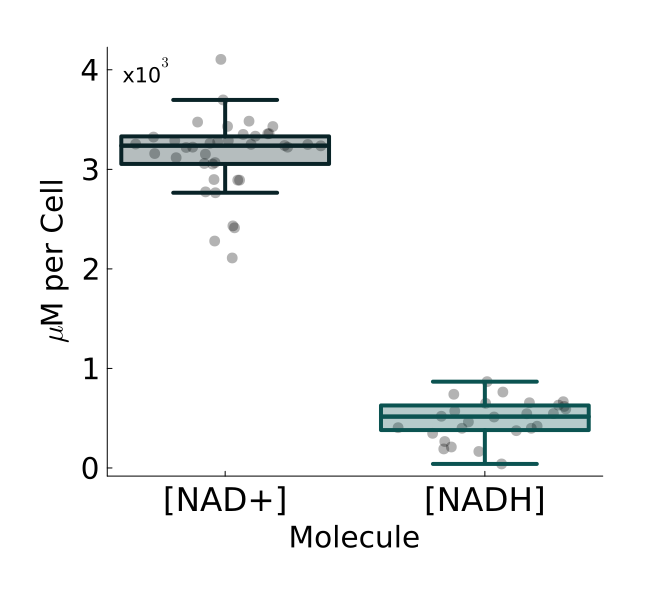

In [6]:
colsN = ["#092327" "#0b5351" "#00a9a5"]

PP = dotplot(transpose([1, 2]), [NAD1mil[(NAD1mil.>0) .* (NAD1mil.<6000)], NADH1mil[NADH1mil.>0]]./1e3,  xlabel = "Molecule", #yaxis=:log, 
    ylabel = L"\mu"*"M per Cell", label = "", 
    grid = false, colour = "black", alpha = 0.3, markersize=6, xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markerstrokewidth=2, linewidth = 4,
    size = (650,600), xticks = (1:2, ["[NAD+]", "[NADH]"]))

boxplot!(transpose([1, 2]), [NAD1mil[(NAD1mil.>0) .* (NAD1mil.<6000)], NADH1mil[NADH1mil.>0]]./1e3, 
    label = "", markeralpha  = 0, 
    grid = false, markersize=0, xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markerstrokewidth=2, linewidth = 4,
    colour = colsN, linecolour = colsN, fillalpha = 0.3)

annotate!(0.7,4, "x10"*L"^{3}")

    
savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\NAD_Quant.svg")

display(PP)

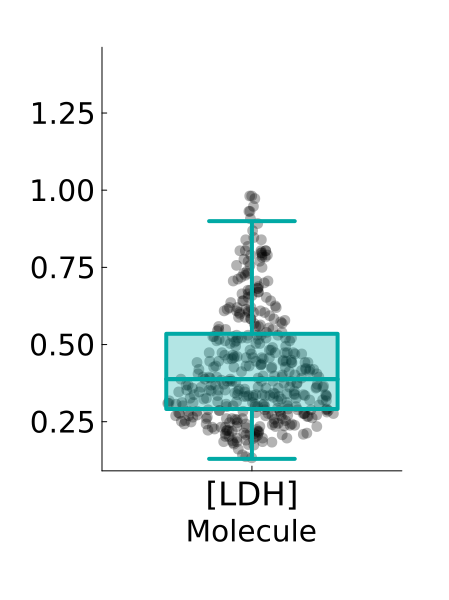

In [5]:
colsN = ["#00a9a5"]

PP = dotplot(transpose([1]), [LDH_RED],  xlabel = "Molecule", #yaxis=:log, 
    ylabel = "", label = "", 
    grid = false, colour = "black", alpha = 0.3, markersize=6, xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markerstrokewidth=2, linewidth = 4,
    size = (450,600), xticks = (1, ["[LDH]"]))

boxplot!(transpose([1]), [LDHDat], 
    label = "", markeralpha  = 0, 
    grid = false, markersize=0, xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markerstrokewidth=2, linewidth = 4,
    colour = colsN, linecolour = colsN, fillalpha = 0.3, xrange=(0.3,1.7))


# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\LDH_Quant.svg")

display(PP)

In [11]:
# LOAD POSTERIOR ANALYSES
covsAll1 = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\CovarsAllItr1.jld")["covsAll1"];
covsAll2 = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\CovarsAllItr2.jld")["covsAll2"];
covsAll3 = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\CovarsAllItr3.jld")["covsAll3"];
H_gainAll = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\EntropyGainAllItrs.jld")["H_gain"];

In [15]:
# LOAD SIMULATIONS
mainD = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ProcessedData\\";

datsD = ["3Mil_0-6mMPyr_Dat","3Mil_0-8mMPyr_Dat","3Mil_1-6mMPyr_Dat","3Mil_3-2mMPyr_Dat", "3Mil_6-0mMPyr_Dat","3Mil_6-4mMPyr_Dat","3Mil_8-3mMPyr_Dat","3Mil_12-8mMPyr_Dat","3Mil_13-1mMPyr_Dat","3Mil_18-0mMPyr_Dat","3Mil_25-6mMPyr_Dat","3Mil_29-6mMPyr_Dat","3Mil_40-0mMPyr_Dat"]

allD = [Matrix(CSV.read(mainD*datsD[i]*".csv", DataFrame)) for i in 1:length(datsD)];

# Inference on OED Results

In [6]:
# Load Posteriors
mainP = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\"

postNms = ["PosteriorCompetitiveRepressionExpScal_Iter1_Try1", "PosteriorCompetitiveRepressionExpScal_Iter2_Try1", "PosteriorCompetitiveRepressionExpScal_Iter3_Try1", "PosteriorCompetitiveRepressionExpScal_Iter4_Try1", "PosteriorCompetitiveRepressionExpScal_Iter4b_Try1"]

posters = Array{Any}(undef, length(postNms))
postersCut = Array{Any}(undef, length(postNms))

for i in 1:length(postNms)
    posters[i] = Matrix(CSV.read(mainP*postNms[i]*".csv", DataFrame));
    postersCut[i] = hcat(posters[i][:,1], posters[i][:,3:12], posters[i][:,15:end])
end

In [43]:
# LOAD POSTERIOR ANALYSES
covs = JLD2.load(mainP*"PosteriorAnalysis\\CovarsAll.jld")["covsAll"];
H_gain = reshape(Float64.(transpose(JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\EntropyGainIndiv.jld")["H_gain"])), 5);

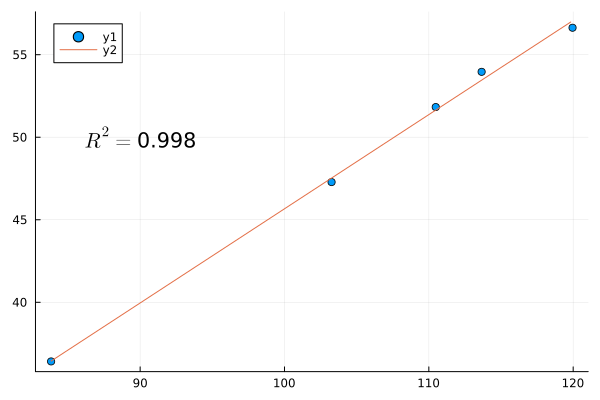

In [44]:
data = DataFrame(X=covs, Y = H_gain)
ols = GLM.lm(@formula(Y ~ X), data)

scatter(covs, H_gain)
plot!(minimum(covs):maximum(covs), predict(ols, DataFrame(X = minimum(covs):maximum(covs))))

annotate!(90, 50, L"R^2 = "*string(round(r2(ols), digits=3)), 14)


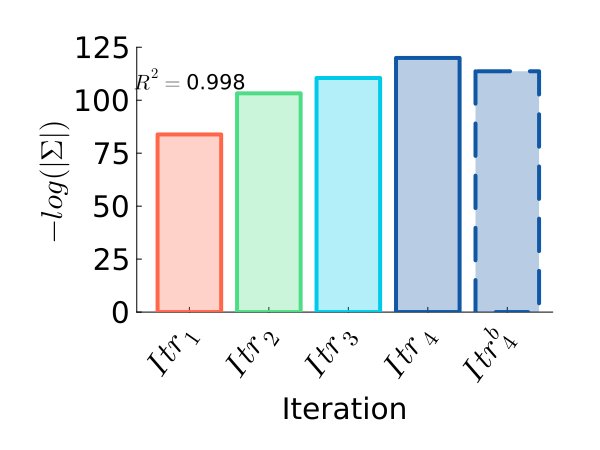

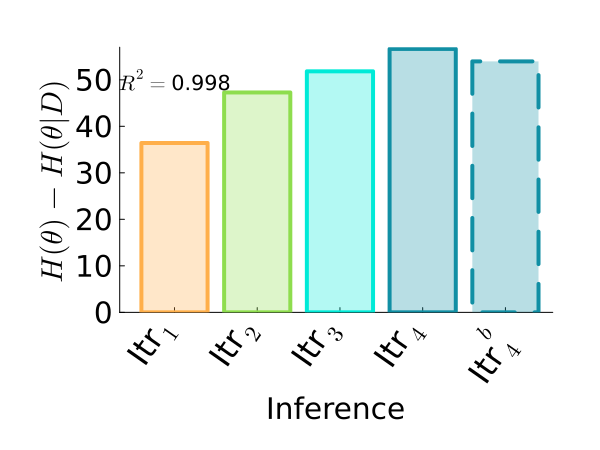

In [45]:
data = DataFrame(X=covs, Y = H_gain)
ols = GLM.lm(@formula(Y ~ X), data)


ppC = bar(covs[1:4], label = "", grid = false, ylabel = L"-log(| \Sigma|)", xlabel="Iteration", xticks = (1:5, [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"]),
    xrotation=45, linewidth = 4, ylim=(0,125), 
    colour = ["#ff674aff", "#4edd85ff", "#00caeaff", "#1158a4ff"], linecolour = ["#ff674aff", "#4edd85ff", "#00caeaff", "#1158a4ff"], fillalpha=0.3,
    xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markerstrokewidth=2, size=(600,450))

    bar!([5], [covs[5]], label = "", grid = false, ylabel = L"-log(| \Sigma|)", xlabel="Iteration", xticks = (1:5, [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"]),
    xrotation=55, colour = ["#1158a4ff"], linecolour = ["#1158a4ff"], linestyle=:dash, linewidth=4, fillalpha=0.3)

    annotate!(1, 110, L"R^2 = "*string(round(r2(ols), digits=3)), 14)


    # savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\CovarMain.svg")

display(ppC)



ppE = bar(H_gain[1:4], label = "", grid = false, ylabel = L"H(\theta) - H(\theta | D)", xlabel="Inference", xticks = (1:5, ["Itr"*L"_1", "Itr"*L"_2", "Itr"*L"_3", "Itr"*L"_4", "Itr"*L"_4^b"]),
    xrotation=45, linewidth = 4, ylim=(0,57), 
    colour = ["#ffaf4a", "#8edd4e", "#00ead7", "#118fa4"], linecolour = ["#ffaf4a", "#8edd4e", "#00ead7", "#118fa4"], fillalpha=0.3,
    xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markerstrokewidth=2, size=(600,450))

    bar!([5], [H_gain[5]], label = "", grid = false, ylabel = L"H(\theta) - H(\theta | D)", xlabel="Inference", xticks = (1:5, ["Itr"*L"_1", "Itr"*L"_2", "Itr"*L"_3", "Itr"*L"_4", "Itr"*L"_4^b"]),
    xrotation=55, colour = ["#118fa4"], linecolour = ["#118fa4"], linestyle=:dash, linewidth=4, fillalpha=0.3)

    annotate!(1, 50, L"R^2 = "*string(round(r2(ols), digits=3)), 14)


    savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\EntroMain.svg")

display(ppE)

In [46]:
OBJ = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\ObjectiveFunctExperiments_PerIter.jld")["OBJ"];

In [47]:
objs1f = reshape(Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\PredictUncertIter1F.csv", DataFrame)), 400);

objs2f = reshape(Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\PredictUncertIter2F.csv", DataFrame)), 400);

objs3f = reshape(Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\PredictUncertIter3F.csv", DataFrame)), 400);

objs4f = reshape(Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\PredictUncertIter4F.csv", DataFrame)), 400);

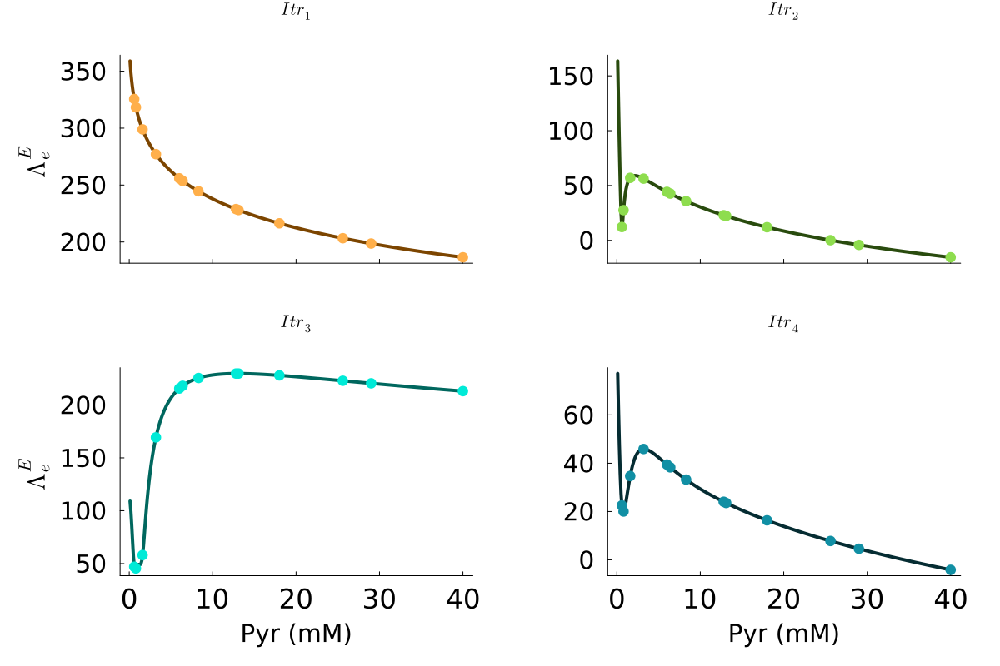

In [48]:
ccpal = ["#ffaf4a", "#8edd4e", "#00ead7", "#118fa4", "#118fa4"];
ccpalli = ["#7c4500ff", "#294b0eff", "#00675eff", "#052c32ff", "#118fa4"];

pyrs = [0.6, 0.8, 1.6, 3.2, 6, 6.4, 8.3, 12.8, 13.1, 18, 25.6, 29, 40]


pp1 = plot(0.1:0.1:40, objs1f, label = "", colour = ccpalli[1])
        scatter!(pyrs, OBJ[1], label = "", grid = false, ylabel = L"\Lambda^E_e", title = L"Itr_1", xformatter = :none, colour = ccpal[1], markerstrokecolor = ccpal[1])
pp2 = plot(0.1:0.1:40, objs2f, label = "", colour = ccpalli[2])
        scatter!(pyrs, OBJ[2], label = "", grid = false, title = L"Itr_2", xformatter = :none, colour = ccpal[2], markerstrokecolor = ccpal[2])
pp3 = plot(0.1:0.1:40, objs3f, label = "", colour = ccpalli[3])
        scatter!(pyrs, OBJ[3], label = "", grid = false, xlabel = "Pyr (mM)", ylabel = L"\Lambda^E_e", title = L"Itr_3", colour = ccpal[3], markerstrokecolor = ccpal[3])
pp4 = plot(0.1:0.1:40, objs4f, label = "", colour = ccpalli[4])
        scatter!(pyrs, OBJ[4], label = "", grid = false, xlabel = "Pyr (mM)", title = L"Itr_4", colour = ccpal[4], markerstrokecolor = ccpal[4])

PPA = plot(pp1,pp2,pp3,pp4, 
            markersize=7, xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markerstrokewidth=2, linewidth = 4,
            size=(1200,800))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\ObjectivePerIter.svg")

display(PPA)

# Y0 Posteriors

No correlation between the three in any posteriors, so all good!

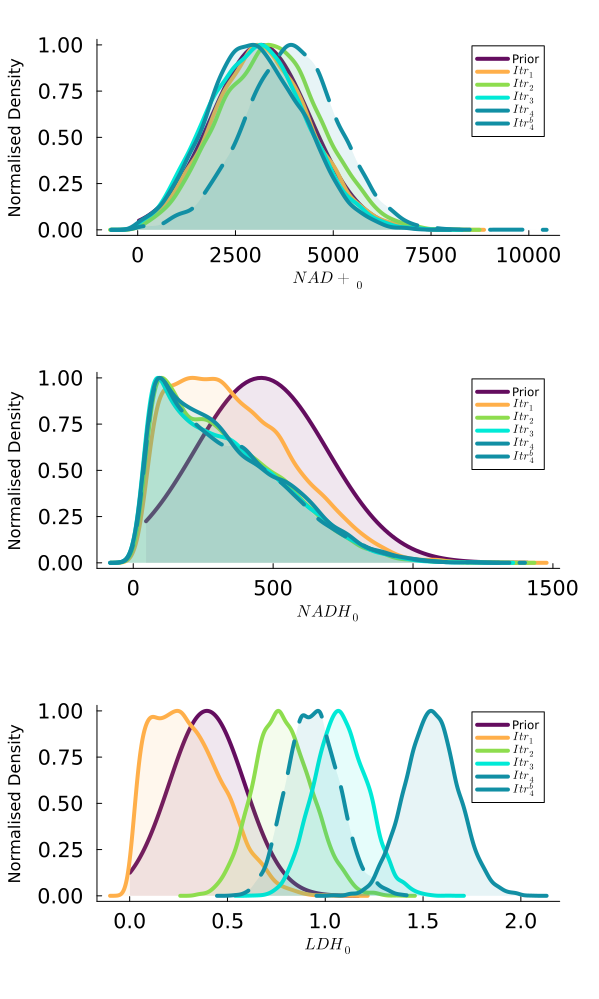

In [49]:
itrs = [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"]
clssr = ["#ff674aff", "#4edd85ff", "#00caeaff", "#1158a4ff", "#1158a4ff"]
clssr = ["#ffaf4a", "#8edd4e", "#00ead7", "#118fa4", "#118fa4"];


# NAD+
x = range(31.46, 8226.67, length=100)
y = pdf.(priotY0[2], x)
ix = abs.(x) .> 1

pp1 = plot(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#640D5F", linewidth=0, label = "", alpha = 0.1, xlabel = L"NAD+_0", ylabel = "Normalised Density", margins=8Plots.mm)
plot!(x[ix], y[ix]./maximum(y), label = "Prior", grid = false, linewidth = 4, colour = "#640D5F")


itrs = [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"]

for i in 1:5
    x = kde(postersCut[i][:,13]).x
    y = kde(postersCut[i][:,13]).density
    ix = abs.(x) .> 1

    if i < 5
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = L"NAD+_0", ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i])
    else
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = L"NAD+_0", ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i], linestyle=:dash)
    end

end

# display(pp1)



# NADH
x = range(45.7, 1409.0, length=100)
y = pdf.(priotY0[1], x)
ix = abs.(x) .> 1

pp2 = plot(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#640D5F", linewidth=0, label = "", alpha = 0.1, xlabel = L"NADH_0", ylabel = "Normalised Density", margins=8Plots.mm)
plot!(x[ix], y[ix]./maximum(y), label = "Prior", grid = false, linewidth = 4, colour = "#640D5F")


itrs = [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"]

for i in 1:5
    x = kde(postersCut[i][:,12]).x
    y = kde(postersCut[i][:,12]).density
    ix = abs.(x) .> 1

    if i < 5
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = L"NADH_0", ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i])
    else
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = L"NADH_0", ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i], linestyle=:dash)
    end

end

# display(pp2)



# LDH
x = range(0.0, 1.168, length=1000)
y = pdf.(priotY0[3], x)
ix = abs.(x) .> 0

pp3 = plot(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#640D5F", linewidth=0, label = "", alpha = 0.1, xlabel = L"LDH_0", ylabel = "Normalised Density", margins=8Plots.mm)
plot!(x[ix], y[ix]./maximum(y), label = "Prior", grid = false, linewidth = 4, colour = "#640D5F")


for i in 1:5
    x = kde(postersCut[i][:,14]).x
    y = kde(postersCut[i][:,14]).density
    ix = abs.(x) .> 0

    if i < 5
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = L"LDH_0", ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i])
    else
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = L"LDH_0", ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i], linestyle=:dash)
    end

end

# display(pp3)


ppr = plot(pp1,pp2,pp3, layout=(3,1), size = (600,1000),xtickfont=font(14), ytickfont=font(14))#, titlefont=font(22))

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\NADTotLDH_Posters.svg")

display(ppr)

# BestWorst Parameter Posteriors

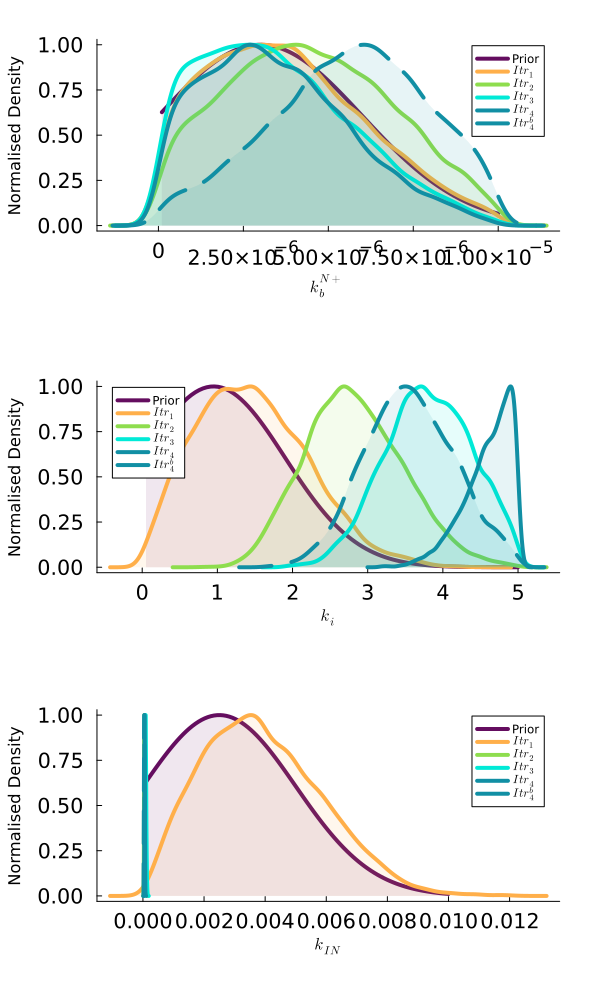

In [84]:
bst=2
med=10
wst=9

clssr = ["#ffaf4a", "#8edd4e", "#00ead7", "#118fa4", "#118fa4"]

namess = [L"T_1^L",L"k_{IN}",L"k_{PL}",L"k_b^N",L"k_u^N",L"k_b^P",L"k_u^P",L"k_u^{N+}",L"k_b^{N+}",L"k_i",L"k_a",L"NADH_0",L"NAD+_0",L"LDH_0"];

# Worst
x = range(priorTheta[vcat(1,3:12)][wst].lower, priorTheta[vcat(1,3:12)][wst].upper, length=100)
y = pdf.(priorTheta[vcat(1,3:12)][wst], x)
ix = abs.(x) .> 0

pp1 = plot(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#640D5F", linewidth=0, label = "", alpha = 0.1, xlabel = namess[wst], ylabel = "Normalised Density", margins=8Plots.mm)
plot!(x[ix], y[ix]./maximum(y), label = "Prior", grid = false, linewidth = 4, colour = "#640D5F")


for i in 1:5
    x = kde(postersCut[i][:,wst]).x
    y = kde(postersCut[i][:,wst]).density
    ix = abs.(x) .> 0

    if i < 5
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = namess[wst], ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i])
    else
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = namess[wst], ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i], linestyle=:dash)
    end

end

# display(pp1)


# Mid
x = range(priorTheta[vcat(1,3:12)][med].lower, priorTheta[vcat(1,3:12)][med].upper, length=100)
y = pdf.(priorTheta[vcat(1,3:12)][med], x)
ix = abs.(x) .> 0

pp2 = plot(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#640D5F", linewidth=0, label = "", alpha = 0.1, xlabel = namess[wst], ylabel = "Normalised Density", margins=8Plots.mm)
plot!(x[ix], y[ix]./maximum(y), label = "Prior", grid = false, linewidth = 4, colour = "#640D5F")


for i in 1:5
    x = kde(postersCut[i][:,med]).x
    y = kde(postersCut[i][:,med]).density
    ix = abs.(x) .> 0

    if i < 5
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = namess[med], ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i])
    else
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = namess[med], ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i], linestyle=:dash)
    end

end

# display(pp2)



# Best
x = range(priorTheta[vcat(1,3:12)][bst].lower, priorTheta[vcat(1,3:12)][bst].upper-1.99, length=100)
y = pdf.(priorTheta[vcat(1,3:12)][bst], x)
ix = abs.(x) .> 0

pp3 = plot(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#640D5F", linewidth=0, label = "", alpha = 0.1, xlabel = namess[wst], ylabel = "Normalised Density", margins=8Plots.mm)
plot!(x[ix], y[ix]./maximum(y), label = "Prior", grid = false, linewidth = 4, colour = "#640D5F")


for i in 1:5
    x = kde(postersCut[i][:,bst]).x
    y = kde(postersCut[i][:,bst]).density
    ix = abs.(x) .> 0

    if i < 5
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = namess[bst], ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i])
    else
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = namess[bst], ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i], linestyle=:dash)
    end

end

# display(pp3)



ppr = plot(pp1,pp2,pp3, layout=(3,1), size = (600,1000),xtickfont=font(14), ytickfont=font(14))#, titlefont=font(22))

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\Theta_Posters.svg")

display(ppr)



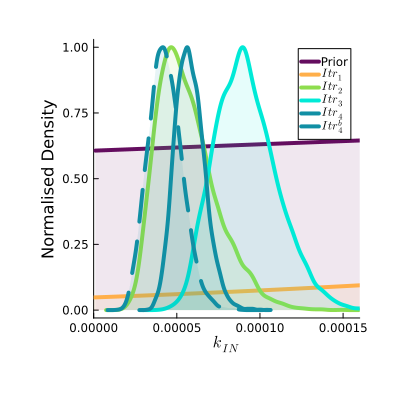

In [90]:
# Best
x = range(priorTheta[vcat(1,3:12)][bst].lower, priorTheta[vcat(1,3:12)][bst].upper-1.99, length=10000)
y = pdf.(priorTheta[vcat(1,3:12)][bst], x)
ix = abs.(x) .> 0

pp3 = plot(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc="#640D5F", linewidth=0, label = "", alpha = 0.1, xlabel = namess[wst], ylabel = "Normalised Density", margins=8Plots.mm)
plot!(x[ix], y[ix]./maximum(y), label = "Prior", grid = false, linewidth = 4, colour = "#640D5F", xlim = (0,0.00016), size=(400,400))


for i in 1:5
    x = kde(postersCut[i][:,bst]).x
    y = kde(postersCut[i][:,bst]).density
    ix = abs.(x) .> 0

    if i < 5
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = namess[bst], ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i])
    else
        plot!(x[ix], y[ix]./maximum(y), fillrange = zero(x[ix]), fc=clssr[i], linewidth=0, label = "", alpha = 0.1, xlabel = namess[bst], ylabel = "Normalised Density", margins=8Plots.mm)
        plot!(x[ix], y[ix]./maximum(y), label = itrs[i], grid = false, linewidth = 4, colour = clssr[i], linestyle=:dash)
    end

end

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\Theta_Posters_BestZoom.svg")


display(pp3)

# Lac vs Pyr Prediction

In [52]:
# loading 2-3 min

LacAUCs = Matrix(CSV.read("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ProcessedData\\LacAUCs.csv", DataFrame));

tt1 = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\SimsAllItrs.jld");
SimsItr1All = tt1["SimsItr1All"];

tt2 = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\SimsItr1AllExps_AUC.jld")
lacSumQuantO = tt2["lacSumQuantO"];

In [53]:
cns5 = [0,0.6,0.8,1.6,3.2,6.0,6.4,8.3,12.8,13.1,18.0,25.6,29.6,40.0]

cns1 = LacAUCs[:,1]
aucs = LacAUCs[:,2:end]

xx = zeros(length(cns1)*3)
indd = collect(1:3:length(cns1)*3)
for i in 1:length(cns1)
    xx[indd[i]:indd[i]+2] .= cns1[i]
end

yy = zeros(length(cns1)*3)
indd = collect(1:3:length(cns1)*3)
for i in 1:length(cns1)
    yy[indd[i]:indd[i]+2] = aucs[i,:]
end

pp = [338,170,0.2024,-17,0.202847]

ss(t,p) = p[1].*(p[2].*exp.(-t.*p[3]).+p[4].*exp.(-t.*p[5]))

fit = LsqFit.curve_fit(ss, xx, yy, pp, maxIter=10000, x_tol = 1e-7, g_tol = 1e-7)


# nRMSE (Does not include the 0, since the low noise in that experiment has a really high effect, masking the rest of the experiments)
fftc = ss(cns5, coef(fit))
nRMSE = sum(((mean((aucs), dims = 2)[2:end] - fftc[2:end]).^2) ./ std((aucs), dims = 2)[2:end].^2)/length(fftc[2:end]) + log(5*log(length(fftc[2:end])))

4.03279925835292

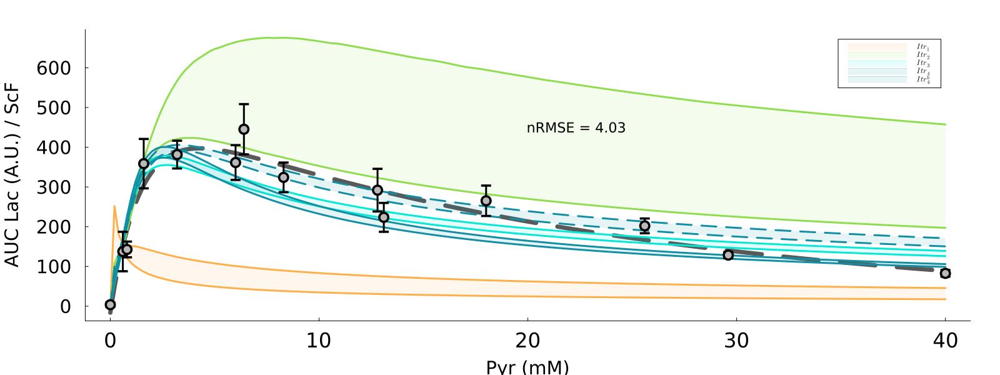

In [108]:
pp1 = plot(0:0.1:40, ss(0:0.1:40, coef(fit)), label="", colour="#595959ff", linewidth = 7,  linestyle = :dash)

pyrRng = 0:0.2:40

i = 1 # posterior!

ccpal = ["#ff674aff", "#4edd85ff", "#00caeaff", "#1158a4ff", "#1158a4ff"];
ccpal = ["#ffaf4a", "#8edd4e", "#00ead7", "#118fa4", "#118fa4"];


nmsit = [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"];


for i in 1:5
    if i <5
        plot!(collect(pyrRng), lacSumQuantO[i,1,:], label = "", color = ccpal[i],
            xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
        plot!(pyrRng, lacSumQuantO[i,2,:], label = "", color = ccpal[i], linewidth=3, alpha = 1)
        plot!(pyrRng, lacSumQuantO[i,2,:], fillrange=convert.(Float64, lacSumQuantO[i,1,:]), color=ccpal[i], fillalpha=0.1, linewidth = 0, label = nmsit[i])
    else
        plot!(collect(pyrRng), lacSumQuantO[i,1,:], label = "", color = ccpal[i],
            xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1, linestyle=:dash)
        plot!(pyrRng, lacSumQuantO[i,2,:], label = "", color = ccpal[i], linewidth=3, alpha = 1, linestyle=:dash)
        plot!(pyrRng, lacSumQuantO[i,2,:], fillrange=convert.(Float64, lacSumQuantO[i,1,:]), color=ccpal[i], fillalpha=0.1, linewidth = 0, label = nmsit[i])
    end
end




scatter!(cns1, mean(aucs, dims = 2), yerror = std(aucs, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
        colour = "#b9b9b9ff", alpha = 1, size = (1600,600), xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=3)

annotate!(20, 450, text("nRMSE = "*string(round(nRMSE, digits = 2)),  :black, :left, 15))


savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\PyrVsLac_AllIters.svg")

display(pp1)

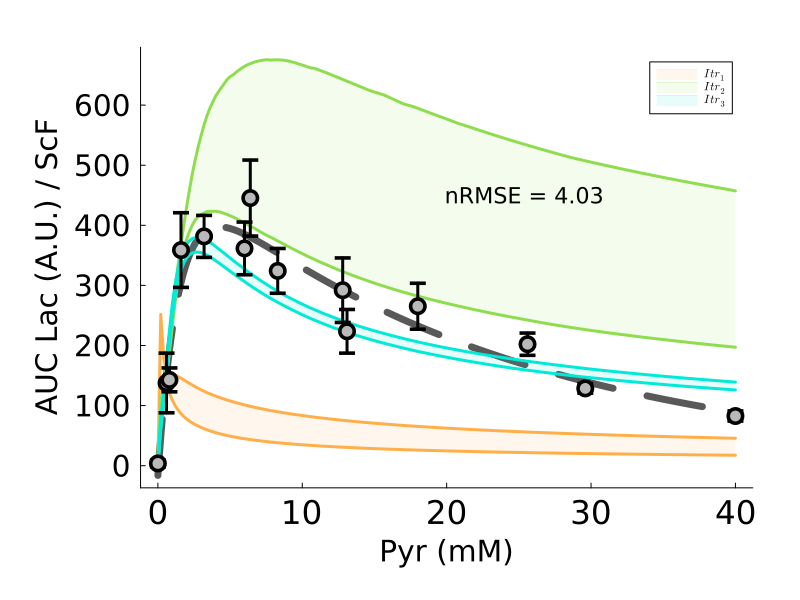

In [112]:
pp1 = plot(0:0.1:40, ss(0:0.1:40, coef(fit)), label="", colour="#595959ff", linewidth = 7,  linestyle = :dash)

pyrRng = 0:0.2:40

i = 1 # posterior!

ccpal = ["#ff674aff", "#4edd85ff", "#00caeaff", "#1158a4ff", "#1158a4ff"];
ccpal = ["#ffaf4a", "#8edd4e", "#00ead7", "#118fa4", "#118fa4"];


nmsit = [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"];


for i in 1:3
    if i <5
        plot!(collect(pyrRng), lacSumQuantO[i,1,:], label = "", color = ccpal[i],
            xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
        plot!(pyrRng, lacSumQuantO[i,2,:], label = "", color = ccpal[i], linewidth=3, alpha = 1)
        plot!(pyrRng, lacSumQuantO[i,2,:], fillrange=convert.(Float64, lacSumQuantO[i,1,:]), color=ccpal[i], fillalpha=0.1, linewidth = 0, label = nmsit[i])
    else
        plot!(collect(pyrRng), lacSumQuantO[i,1,:], label = "", color = ccpal[i],
            xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1, linestyle=:dash)
        plot!(pyrRng, lacSumQuantO[i,2,:], label = "", color = ccpal[i], linewidth=3, alpha = 1, linestyle=:dash)
        plot!(pyrRng, lacSumQuantO[i,2,:], fillrange=convert.(Float64, lacSumQuantO[i,1,:]), color=ccpal[i], fillalpha=0.1, linewidth = 0, label = nmsit[i])
    end
end




scatter!(cns1, mean(aucs, dims = 2), yerror = std(aucs, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
        colour = "#b9b9b9ff", alpha = 1, size = (800,600), xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=3)

annotate!(20, 450, text("nRMSE = "*string(round(nRMSE, digits = 2)),  :black, :left, 15))


savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\PyrVsLac_AllIters_Init.svg")

display(pp1)

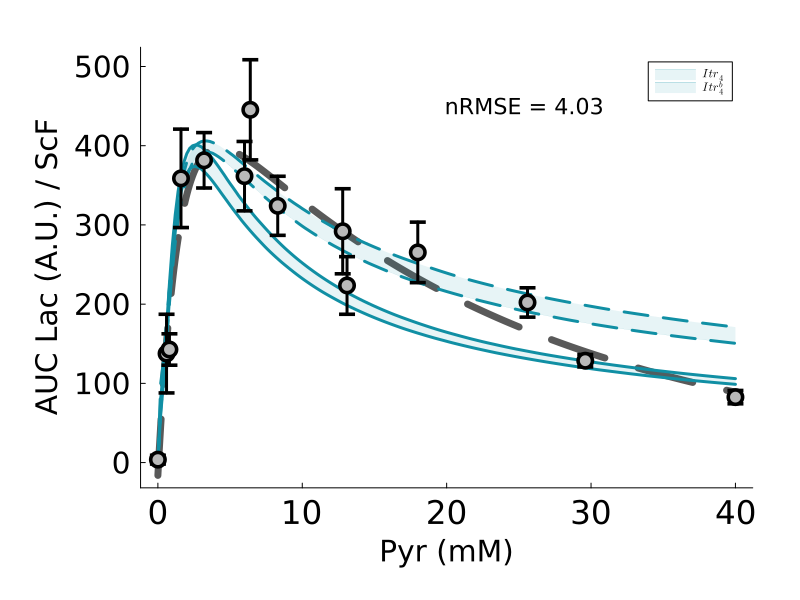

In [113]:
pp1 = plot(0:0.1:40, ss(0:0.1:40, coef(fit)), label="", colour="#595959ff", linewidth = 7,  linestyle = :dash)

pyrRng = 0:0.2:40

i = 1 # posterior!

ccpal = ["#ff674aff", "#4edd85ff", "#00caeaff", "#1158a4ff", "#1158a4ff"];
ccpal = ["#ffaf4a", "#8edd4e", "#00ead7", "#118fa4", "#118fa4"];


nmsit = [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"];


for i in 4:5
    if i <5
        plot!(collect(pyrRng), lacSumQuantO[i,1,:], label = "", color = ccpal[i],
            xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1)
        plot!(pyrRng, lacSumQuantO[i,2,:], label = "", color = ccpal[i], linewidth=3, alpha = 1)
        plot!(pyrRng, lacSumQuantO[i,2,:], fillrange=convert.(Float64, lacSumQuantO[i,1,:]), color=ccpal[i], fillalpha=0.1, linewidth = 0, label = nmsit[i])
    else
        plot!(collect(pyrRng), lacSumQuantO[i,1,:], label = "", color = ccpal[i],
            xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false, linewidth=3, alpha = 1, linestyle=:dash)
        plot!(pyrRng, lacSumQuantO[i,2,:], label = "", color = ccpal[i], linewidth=3, alpha = 1, linestyle=:dash)
        plot!(pyrRng, lacSumQuantO[i,2,:], fillrange=convert.(Float64, lacSumQuantO[i,1,:]), color=ccpal[i], fillalpha=0.1, linewidth = 0, label = nmsit[i])
    end
end




scatter!(cns1, mean(aucs, dims = 2), yerror = std(aucs, dims = 2), label = "", grid = false, xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.) / ScF", width=3, 
        colour = "#b9b9b9ff", alpha = 1, size = (800,600), xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=3)

annotate!(20, 450, text("nRMSE = "*string(round(nRMSE, digits = 2)),  :black, :left, 15))


savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\PyrVsLac_AllIters_Fin.svg")

display(pp1)

# BIC Per Iteration

In [94]:
# LOAD SIMULATIONS
mainD = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ProcessedData\\";

datsD = ["3Mil_0-6mMPyr_Dat","3Mil_0-8mMPyr_Dat","3Mil_1-6mMPyr_Dat","3Mil_3-2mMPyr_Dat", "3Mil_6-0mMPyr_Dat","3Mil_6-4mMPyr_Dat","3Mil_8-3mMPyr_Dat","3Mil_12-8mMPyr_Dat","3Mil_13-1mMPyr_Dat","3Mil_18-0mMPyr_Dat","3Mil_25-6mMPyr_Dat","3Mil_29-6mMPyr_Dat","3Mil_40-0mMPyr_Dat"]

allD = [Matrix(CSV.read(mainD*datsD[i]*".csv", DataFrame)) for i in 1:length(datsD)];

In [95]:
tt1 = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\SimsAllItrsIndExp.jld");
SimsItr1All2 = tt1["SimsItr1All2"];

In [98]:
BICMSE = Array{Any}(undef, 2, length(posters), length(datsD)); # First BIC, second nRMSE

for i in 1:length(posters)   
    for j in 1:length(datsD)

        tmp_BIC = zeros(length(SimsItr1All2[1,i,j]))
        tmp_nRMSE = zeros(length(SimsItr1All2[1,i,j]))

        tmp_m = allD[j][2:end,4]
        tmp_s = allD[j][2:end,5]
        tin = length(tmp_m)

        for s in 1:length(SimsItr1All2[1,i,j])
            tmp_p = SimsItr1All2[1,i,j][s][(80-tin)+1:end,13,1]

            tmp_BIC[s] = sum(((tmp_p-tmp_m).^2)./(tmp_s.^2)) .+ (11*log(length(tmp_p))) # BIC_Lac_F
            tmp_nRMSE[s] = sqrt(sum(((tmp_p-tmp_m).^2)./(tmp_s.^2))/length(tmp_p)) .+ (log(11*log(length(tmp_p))))
        end

        BICMSE[1,i,j] = tmp_BIC;
        BICMSE[2,i,j] = tmp_nRMSE;
    end
end

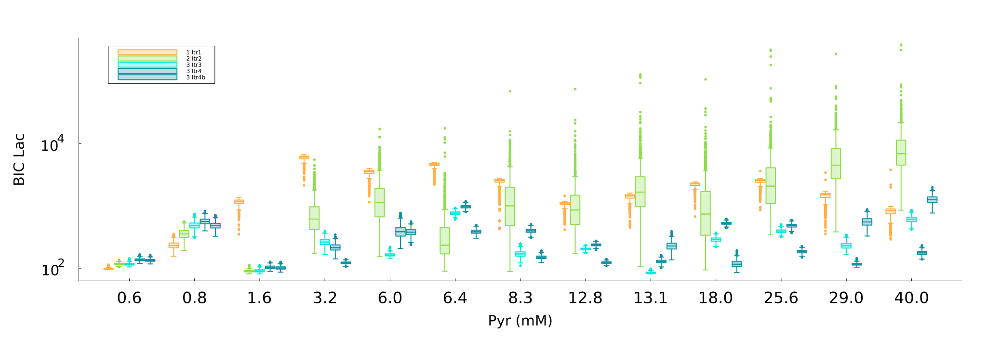

In [99]:
t = String[]
for i in 1:1000
    push!(t,"1 Itr1")
end
for i in 1:1000
    push!(t,"2 Itr2")
end
for i in 1:1000
    push!(t,"3 Itr3")
end
for i in 1:1000
    push!(t,"3 Itr4")
end
for i in 1:1000
    push!(t,"3 Itr4b")
end

ca = repeat(t, length(cns)-1);


Random.seed!(164598464)

xa = String[]
for j in 1:length(cns)-1
    for i in 1:1000*5
        push!(xa,string(cns[j+1]))
    end
end


va2b = []
for i in 1:length(cns)-1
    ttp = vcat(BICMSE[1,1,i][StatsBase.sample(1:size(BICMSE[1,1,i])[1], 1000, replace = false)], 
               BICMSE[1,2,i][StatsBase.sample(1:size(BICMSE[1,1,i])[1], 1000, replace = false)], 
               BICMSE[1,3,i][StatsBase.sample(1:size(BICMSE[1,1,i])[1], 1000, replace = false)],
               BICMSE[1,4,i][StatsBase.sample(1:size(BICMSE[1,1,i])[1], 1000, replace = false)],
               BICMSE[1,5,i][StatsBase.sample(1:size(BICMSE[1,1,i])[1], 1000, replace = false)])
    for j in 1:length(ttp)
    push!(va2b, ttp[j])
    end
end


va2 = []
for i in 1:length(cns)-1
    ttp = vcat(BICMSE[2,1,i][StatsBase.sample(1:size(BICMSE[1,1,i])[1], 1000, replace = false)], 
               BICMSE[2,2,i][StatsBase.sample(1:size(BICMSE[1,1,i])[1], 1000, replace = false)], 
               BICMSE[2,3,i][StatsBase.sample(1:size(BICMSE[1,1,i])[1], 1000, replace = false)],
               BICMSE[2,4,i][StatsBase.sample(1:size(BICMSE[1,1,i])[1], 1000, replace = false)],
               BICMSE[2,5,i][StatsBase.sample(1:size(BICMSE[1,1,i])[1], 1000, replace = false)])
    for j in 1:length(ttp)
    push!(va2, ttp[j])
    end
end


ccpal2 = ["#ffaf4a" "#8edd4e" "#00ead7" "#118fa4" "#118fa4"]



ss1 = groupedboxplot(xa, va2b, group = ca, yscale=:log10, grid = false, colour = ccpal2, ylabel = "BIC Lac", xlabel = "Pyr (mM)", 
        size = (2075,700), xtickfont=font(22), ytickfont=font(20), margins=18Plots.mm, guidefontsize = 20, markersize = 3, markerstrokewidth=2, linewidth = 2,
        markerstrokecolor = ccpal2, linecolor = ccpal2, fillalpha=0.3)
# annotate!(6, 10^5,L"Itr_2", 15)

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\BIC_PerExper_PerIter.svg")

display(ss1)

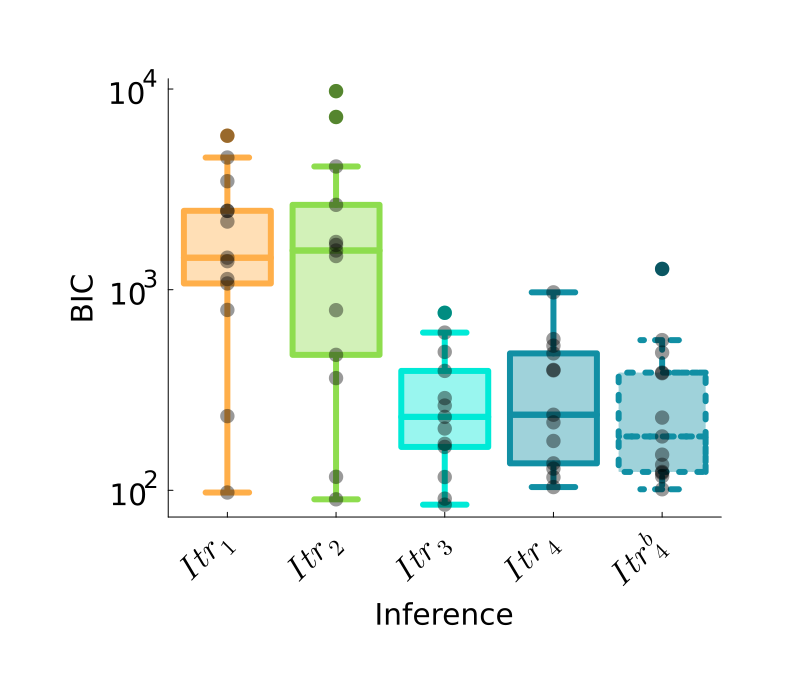

In [100]:
BICmean = [[mean(BICMSE[1,i,j]) for j in 1:13] for i in 1:5]

ccpal2 = ["#ffaf4a" "#8edd4e" "#00ead7" "#118fa4"]

bbp2 = boxplot(1:4, BICmean[1:4], grid = false, yscale=:log10, label = "", 
        colour = ccpal2, linecolor = ccpal2, markerstrokecolor = ccpal2, fillalpha=0.4,
        linewidth=6, size = (800,700), xtickfont=font(22), ytickfont=font(20), margins=18Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=2,
        xlabel="Inference", ylabel = "BIC", xticks = (transpose([1:5]), reshape([L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"], 5, 1)), xrotation =45)

for j in 1:4
        for i in 1:13 
                scatter!([j], [BICmean[j][i]], color = "black", markersize=8, linecolor="black", markerstrokecolor="black", label ="", alpha = 0.4)
        end
end
# clss = cgrad(:roma, 13, categorical = true)       


# dotplot!([5], BICmean[5], color = "black", markersize=8, linecolor="black", markerstrokecolor="black", label ="", alpha=0.4)
boxplot!([5], BICmean[5], linestyle=:dot, label = "",
        colour = "#118fa4", linecolor = "#118fa4", markerstrokecolor = "#118fa4", fillalpha=0.4, markeralpha=1,
        linewidth=6, markersize = 8, markerstrokewidth=2)
for i in 1:13 
        scatter!([5], [BICmean[5][i]], color = "black", markersize=8, linecolor="black", markerstrokecolor="black", label ="", alpha = 0.4)
end

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\BIC_PerIter.svg")


display(bbp2)

In [ ]:
# Check the cumulative BIC to select the best model. In this case it is the one from Iteration 3
[sum(BICmean[i]) for i in 1:5]

5-element Vector{Float64}:
 27160.421296547513
 32039.630186488394
  3876.817916938537
  4455.013370367083
  4249.231559147579

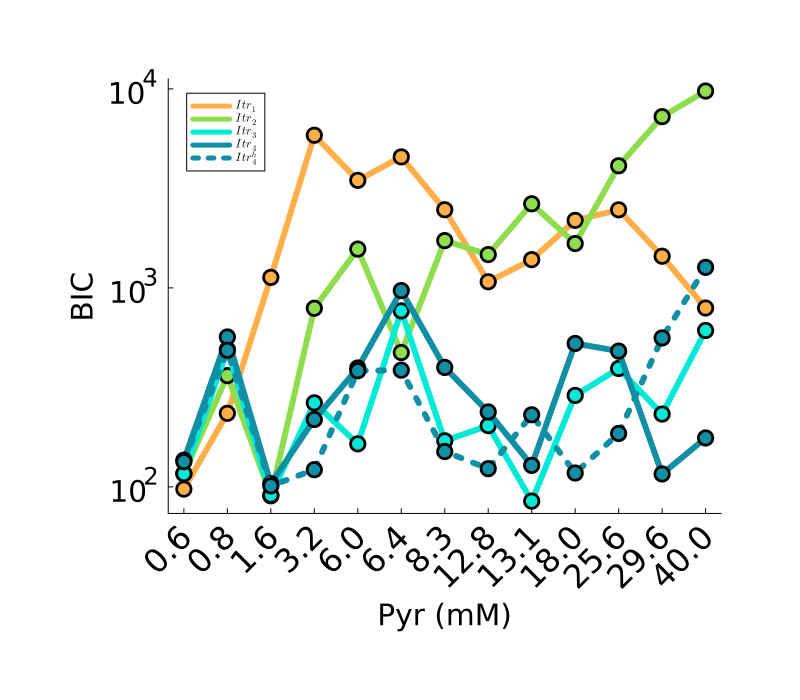

In [60]:
ccpal2 = ["#ffaf4a" "#8edd4e" "#00ead7" "#118fa4" "#118fa4"]
nmsit = [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"];
cns = ["06","08","16","32","60","64","83","128","131","180","256","296","400"]
cns2 = [cns[i][1:end-1]*"."*cns[i][end] for i in 1:length(cns)]

qqq = plot(BICmean[1], yscale=:log10, colour=ccpal2[1], grid=false, label = nmsit[1], xlabel="Pyr (mM)", ylabel = "BIC",
        linewidth=6, size = (800,700), xtickfont=font(22), ytickfont=font(20), margins=18Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=2,
        xticks = (transpose([1:13]), reshape(cns2, 13, 1)), xrotation =45)

scatter!(1:13, BICmean[1], label = "", colour=ccpal2[1], 
        linewidth=6, size = (800,700), xtickfont=font(22), ytickfont=font(20), margins=18Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=2)

for i in 2:5
    if i<5
        plot!(BICmean[i], colour=ccpal2[i], label=nmsit[i],
        linewidth=6, size = (800,700), xtickfont=font(22), ytickfont=font(20), margins=18Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=2)
    else
        plot!(BICmean[i], linestyle=:dot, colour=ccpal2[i], label=nmsit[i],
        linewidth=6, size = (800,700), xtickfont=font(22), ytickfont=font(20), margins=18Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=2)
    end
    scatter!(1:13, BICmean[i], label = "", colour=ccpal2[i],
    linewidth=6, size = (800,700), xtickfont=font(22), ytickfont=font(20), margins=18Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=2)
end

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\BIC_PerExper.svg")


display(qqq)

# BIC vs Coeficient of Variation

In [61]:
mainD = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ProcessedData\\";
# datsD = ["3Mil_0-0mMPyr_Dat","3Mil_0-6mMPyr_Dat","3Mil_0-8mMPyr_Dat","3Mil_1-6mMPyr_Dat","3Mil_3-2mMPyr_Dat", "3Mil_4-9mMPyr_Dat","3Mil_6-0mMPyr_Dat","3Mil_6-4mMPyr_Dat","3Mil_8-3mMPyr_Dat","3Mil_12-8mMPyr_Dat","3Mil_13-1mMPyr_Dat","3Mil_18-0mMPyr_Dat","3Mil_25-6mMPyr_Dat","3Mil_29-6mMPyr_Dat","3Mil_40-0mMPyr_Dat"]

datsD = ["3Mil_0-0mMPyr_Dat","3Mil_0-6mMPyr_Dat","3Mil_0-8mMPyr_Dat","3Mil_1-6mMPyr_Dat","3Mil_3-2mMPyr_Dat", "3Mil_6-0mMPyr_Dat","3Mil_6-4mMPyr_Dat","3Mil_8-3mMPyr_Dat","3Mil_12-8mMPyr_Dat","3Mil_13-1mMPyr_Dat","3Mil_18-0mMPyr_Dat","3Mil_25-6mMPyr_Dat","3Mil_29-6mMPyr_Dat","3Mil_40-0mMPyr_Dat"]

allD = [Matrix(CSV.read(mainD*datsD[i]*".csv", DataFrame)) for i in 1:length(datsD)];

In [62]:
cns = [0,0.6,0.8,1.6,3.2,6,6.4,8.3,12.8,13.1,18,25.6,29,40]


CVs = []
CVms = zeros(length(datsD),3)
for i in 1:length(datsD)
    CV = allD[i][2:40,5]./allD[i][2:40,4]
    CVms[i,1] = mean(CV[2:end])
    CVms[i,2] = std(CV[2:end])
    CVms[i,3] = sum(CV[2:end])
    push!(CVs, CV)
end

CVsRe = zeros(39,length(CVs[2:end]))
for i in 1:length(CVs[2:end])
    CVsRe[:,i] = CVs[i+1]
end

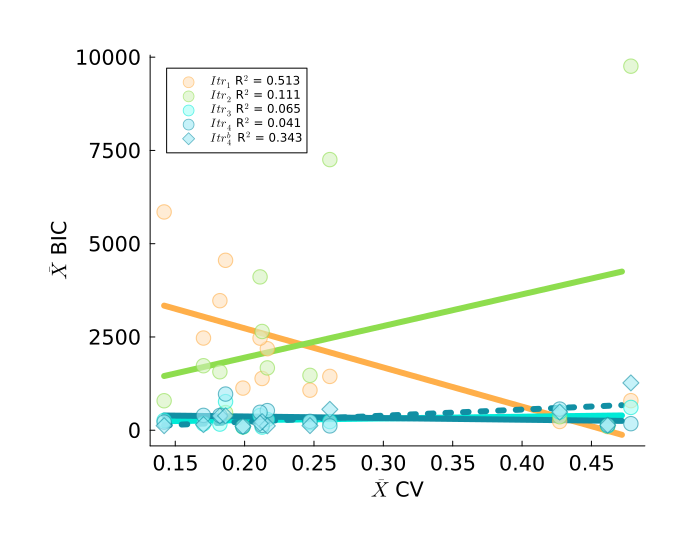

In [99]:
ccpal2 = ["#ffaf4a" "#8edd4e" "#00ead7" "#118fa4" "#118fa4"]
ccpal2al = ["#ffe0b9ff" "#d4f2bcff" "#a2fff7ff" "#a1e9f5ff" "#a1e9f5ff"]

nmsit = [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"];
cns = ["06","08","16","32","60","64","83","128","131","180","256","296","400"]

CVmean = [mean(CVs[i][2:end]) for i in 2:length(CVs)]

data1 = DataFrame(X=CVmean, Y=reshape(BICmean[1], length(BICmean[1])))
ols1 = lm(@formula(Y ~ X), data1)



ppc1 = plot(collect(minimum(CVmean):0.01:maximum(CVmean)), predict(ols1, DataFrame(X = collect(minimum(CVmean):0.01:maximum(CVmean)))), color = ccpal2[1], label = "", linewidth=6, 
    size=(800,550), margin=12Plots.mm,xtickfont=font(14), 
        ytickfont=font(14), guidefont=font(14), titlefont=font(14), xlabel=L"\bar{X}"*" CV", ylabel=L"\bar{X}"*" BIC")
        


for i in 2:5
    data1 = DataFrame(X=CVmean, Y=reshape(BICmean[i], length(BICmean[i])))
    ols1 = lm(@formula(Y ~ X), data1)

    if i < 5
        plot!(collect(minimum(CVmean):0.01:maximum(CVmean)), predict(ols1, DataFrame(X = collect(minimum(CVmean):0.01:maximum(CVmean)))), color = ccpal2[i], label = "", linewidth=6, 
        size=(700,550), margin=12Plots.mm,xtickfont=font(14), 
            ytickfont=font(14), guidefont=font(14), titlefont=font(14))
    else
        plot!(collect(minimum(CVmean):0.01:maximum(CVmean)), predict(ols1, DataFrame(X = collect(minimum(CVmean):0.01:maximum(CVmean)))), color = ccpal2[i], label = "", linewidth=6, 
        size=(700,550), margin=12Plots.mm,xtickfont=font(14), 
            ytickfont=font(14), guidefont=font(14), titlefont=font(14), linestyle=:dot)
    end
end

for i in 1:5

    data1 = DataFrame(X=CVmean, Y=reshape(BICmean[i], length(BICmean[i])))
    ols1 = lm(@formula(Y ~ X), data1)

    if i <5
        scatter!(CVmean, BICmean[i], label = nmsit[i]*" R"*L"^2"*" = "*string(round(r2(ols1), digits = 3)), grid = false, 
            color=ccpal2al[i], markerstrokecolor=ccpal2[i], markersize=8, alpha=0.6)
    else
        scatter!(CVmean, BICmean[i], label = nmsit[i]*" R"*L"^2"*" = "*string(round(r2(ols1), digits = 3)), grid = false, 
            color=ccpal2al[i], markerstrokecolor=ccpal2[i], markersize=8, markershape=:diamond, alpha=0.6)
    end
end

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\BIC_VS_CV.svg")


display(ppc1)

# Lac Prediction All Experiments (Best Posterior)

In [6]:
mainD = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ProcessedData\\";
# datsD = ["3Mil_0-0mMPyr_Dat","3Mil_0-6mMPyr_Dat","3Mil_0-8mMPyr_Dat","3Mil_1-6mMPyr_Dat","3Mil_3-2mMPyr_Dat", "3Mil_4-9mMPyr_Dat","3Mil_6-0mMPyr_Dat","3Mil_6-4mMPyr_Dat","3Mil_8-3mMPyr_Dat","3Mil_12-8mMPyr_Dat","3Mil_13-1mMPyr_Dat","3Mil_18-0mMPyr_Dat","3Mil_25-6mMPyr_Dat","3Mil_29-6mMPyr_Dat","3Mil_40-0mMPyr_Dat"]

datsD = ["3Mil_0-0mMPyr_Dat","3Mil_0-6mMPyr_Dat","3Mil_0-8mMPyr_Dat","3Mil_1-6mMPyr_Dat","3Mil_3-2mMPyr_Dat", "3Mil_6-0mMPyr_Dat","3Mil_6-4mMPyr_Dat","3Mil_8-3mMPyr_Dat","3Mil_12-8mMPyr_Dat","3Mil_13-1mMPyr_Dat","3Mil_18-0mMPyr_Dat","3Mil_25-6mMPyr_Dat","3Mil_29-6mMPyr_Dat","3Mil_40-0mMPyr_Dat"]

allD = [Matrix(CSV.read(mainD*datsD[i]*".csv", DataFrame)) for i in 1:length(datsD)];

cns = [0,0.6,0.8,1.6,3.2,6,6.4,8.3,12.8,13.1,18,25.6,29,40];


In [7]:
tt1 = JLD2.load("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_Y0Measured\\Results\\PosteriorAnalysis\\SimsAllItrsIndExp.jld");
SimsItr1All2 = tt1["SimsItr1All2"];

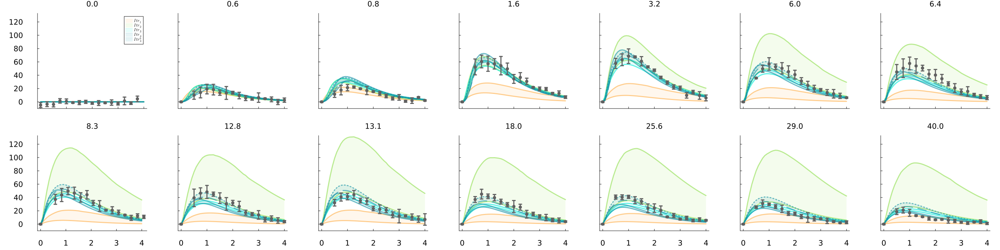

In [9]:
allXps = Array{Any}(undef, 14)

ccpal = ["#ffaf4a", "#8edd4e", "#00ead7", "#118fa4", "#118fa4"];
# ccpal = ["#8cb369", "#f4e285", "#f4a259", "#5b8e7d", "#bc4b51"]
# ccpal = ["#73d2de", "#218380", "#8f2d56", "#ffbc42", "#d81159"]
# ccpal = ["#0ead69", "#3bceac", "#ffd23f", "#ee4266", "#540d6e"]


nmsit = [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"];

stp = 3
ndd = 49
ndd2 = 46

for i in 1:14

    allXps[i] = plot()

    for j in 1:5
        if i == 1
            tmp1 = zeros(80)
            tmp2 = zeros(80)
        else
            tmp1 = SimsItr1All2[2,j,i-1][1]
            tmp2 = SimsItr1All2[2,j,i-1][2]
        end
        if j <5
            plot!(collect(0:5:395)[1:ndd]./60, tmp1[1:ndd], label = "", color = ccpal[j],
                linewidth=3, alpha = 0.6)
            plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], label = "", color = ccpal[j], linewidth=3, alpha = 0.6)
        else
            plot!(collect(0:5:395)[1:ndd]./60, tmp1[1:ndd], label = "", color = ccpal[j],
                linewidth=3, alpha = 0.6, linestyle=:dot)
            plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], label = "", color = ccpal[j], linewidth=3, alpha = 0.6, linestyle=:dash)
        end

        if i == 1
            plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], fillrange=convert.(Float64, tmp1), color=ccpal[j], fillalpha=0.1, linewidth = 0, label = nmsit[j])
        else
            plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], fillrange=convert.(Float64, tmp1), color=ccpal[j], fillalpha=0.1, linewidth = 0, label = "")
        end
    end

    if i == 1
        scatter!(allD[i][1:stp:ndd2,1]./60, allD[i][1:stp:ndd2,4], yerror = allD[i][1:stp:ndd2,5], label = "", grid = false, ylim=(-10,133), title = cns[i], ylabel = "Lac (A.U.)", xformatter = :none,
                        markersize=5, linewidth= 3, color="#606060ff", markercolor="#606060ff", linecolor="#606060ff", markerstrokecolor="#606060ff")
    elseif i == 8
        scatter!(allD[i][1:stp:ndd2,1]./60, allD[i][1:stp:ndd2,4], yerror = allD[i][1:stp:ndd2,5], label = "", grid = false, ylim=(-10,133), title = cns[i], ylabel = "Lac (A.U.)", xlabel = "time (min)",
                        markersize=5, linewidth= 3, color="#606060ff", markercolor="#606060ff", linecolor="#606060ff", markerstrokecolor="#606060ff")
    elseif i > 8
        scatter!(allD[i][1:stp:ndd2,1]./60, allD[i][1:stp:ndd2,4], yerror = allD[i][1:stp:ndd2,5], label = "", grid = false, ylim=(-10,133), title = cns[i], xlabel = "time (min)", yformatter = :none,
                        markersize=5, linewidth= 3, color="#606060ff", markercolor="#606060ff", linecolor="#606060ff", markerstrokecolor="#606060ff")
    else
        scatter!(allD[i][1:stp:ndd2,1]./60, allD[i][1:stp:ndd2,4], yerror = allD[i][1:stp:ndd2,5], label = "", grid = false, ylim=(-10,133), title = cns[i],
                        markersize=5, linewidth= 3, color="#606060ff", markercolor="#606060ff", linecolor="#606060ff", markerstrokecolor="#606060ff", xformatter = :none, yformatter = :none)
    end


end


MMP = plot(allXps..., layout=(2,7), size = (2800,700), margin=5Plots.mm,xtickfont=font(14), 
        ytickfont=font(14), guidefont=font(14), titlefont=font(14))

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\SimsDat.svg")

display(MMP)

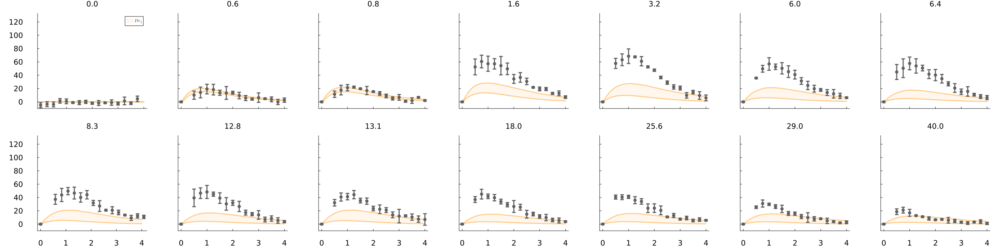

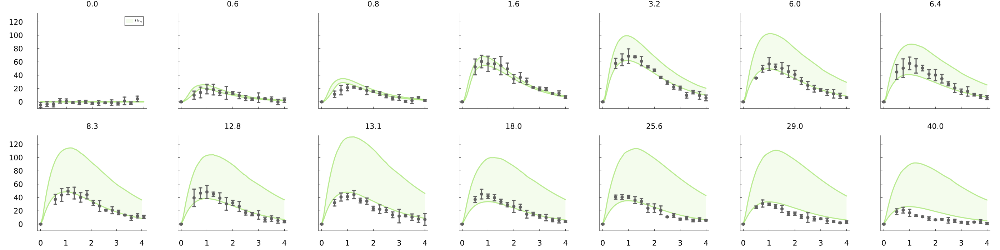

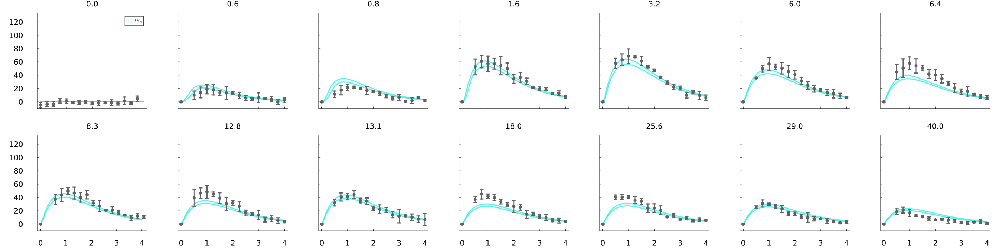

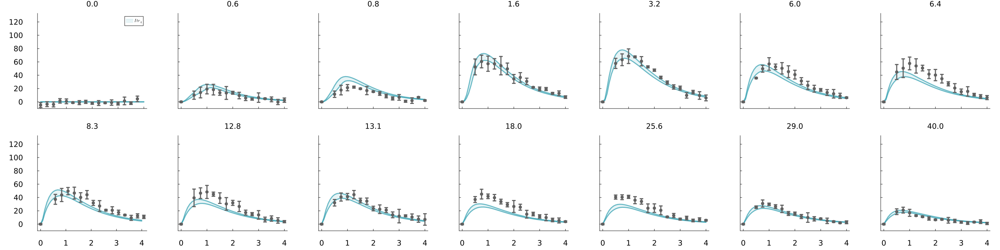

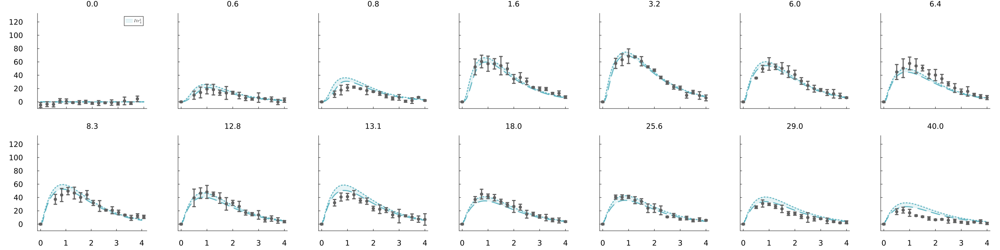

In [ ]:
for j in 1:5

    allXps = Array{Any}(undef, 14)

    ccpal = ["#ffaf4a", "#8edd4e", "#00ead7", "#118fa4", "#118fa4"];
    nmsit = [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"];

    stp = 3
    ndd = 49
    ndd2 = 46

    for i in 1:14

        allXps[i] = plot()

        
        if i == 1
            tmp1 = zeros(80)
            tmp2 = zeros(80)
        else
            tmp1 = SimsItr1All2[2,j,i-1][1]
            tmp2 = SimsItr1All2[2,j,i-1][2]
        end
        if j <5
            plot!(collect(0:5:395)[1:ndd]./60, tmp1[1:ndd], label = "", color = ccpal[j],
                linewidth=3, alpha = 0.6)
            plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], label = "", color = ccpal[j], linewidth=3, alpha = 0.6)
        else
            plot!(collect(0:5:395)[1:ndd]./60, tmp1[1:ndd], label = "", color = ccpal[j],
                linewidth=3, alpha = 0.6, linestyle=:dot)
            plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], label = "", color = ccpal[j], linewidth=3, alpha = 0.6, linestyle=:dash)
        end

        if i == 1
            plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], fillrange=convert.(Float64, tmp1), color=ccpal[j], fillalpha=0.1, linewidth = 0, label = nmsit[j])
        else
            plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], fillrange=convert.(Float64, tmp1), color=ccpal[j], fillalpha=0.1, linewidth = 0, label = "")
        end
        

        if i == 1
            scatter!(allD[i][1:stp:ndd2,1]./60, allD[i][1:stp:ndd2,4], yerror = allD[i][1:stp:ndd2,5], label = "", grid = false, ylim=(-10,133), title = cns[i], ylabel = "Lac (A.U.)", xformatter = :none,
                            markersize=5, linewidth= 3, color="#606060ff", markercolor="#606060ff", linecolor="#606060ff", markerstrokecolor="#606060ff")
        elseif i == 8
            scatter!(allD[i][1:stp:ndd2,1]./60, allD[i][1:stp:ndd2,4], yerror = allD[i][1:stp:ndd2,5], label = "", grid = false, ylim=(-10,133), title = cns[i], ylabel = "Lac (A.U.)", xlabel = "time (min)",
                            markersize=5, linewidth= 3, color="#606060ff", markercolor="#606060ff", linecolor="#606060ff", markerstrokecolor="#606060ff")
        elseif i > 8
            scatter!(allD[i][1:stp:ndd2,1]./60, allD[i][1:stp:ndd2,4], yerror = allD[i][1:stp:ndd2,5], label = "", grid = false, ylim=(-10,133), title = cns[i], xlabel = "time (min)", yformatter = :none,
                            markersize=5, linewidth= 3, color="#606060ff", markercolor="#606060ff", linecolor="#606060ff", markerstrokecolor="#606060ff")
        else
            scatter!(allD[i][1:stp:ndd2,1]./60, allD[i][1:stp:ndd2,4], yerror = allD[i][1:stp:ndd2,5], label = "", grid = false, ylim=(-10,133), title = cns[i],
                            markersize=5, linewidth= 3, color="#606060ff", markercolor="#606060ff", linecolor="#606060ff", markerstrokecolor="#606060ff", xformatter = :none, yformatter = :none)
        end


    end


    MMP = plot(allXps..., layout=(2,7), size = (2800,700), margin=5Plots.mm,xtickfont=font(14), 
            ytickfont=font(14), guidefont=font(14), titlefont=font(14))

    # savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\SimsDat_Itr"*string(j)*".svg")

    display(MMP)

end

# All Model States Predictions

In [8]:
i=4 # Experiment
j=3 # Model Iteration

s=3 # Model State

# Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,14,14);
for k in 1:5
    for m in 1:14
        lacPirorSims = zeros(size(SimsItr1All2[1,k,i-1][1])[1], 4000)
        [lacPirorSims[:,f] = SimsItr1All2[1,k,i-1][f][:,m,1] for f in 1:4000 ];

        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end


In [12]:
# Check the cumulative BIC to select the best model. In this case it is the one from Iteration 3
[sum(BICmean[i]) for i in 1:5]

LoadError: UndefVarError: `BICmean` not defined in `Main`
Suggestion: check for spelling errors or missing imports.

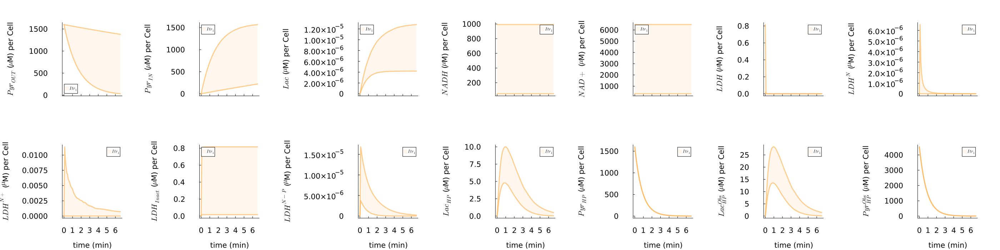

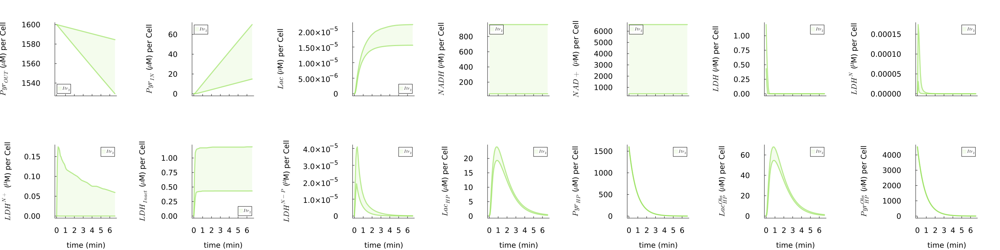

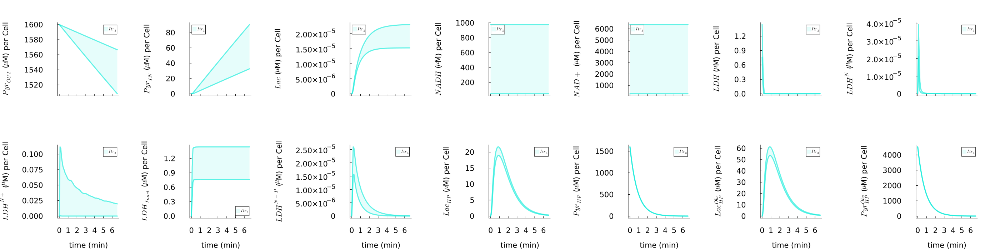

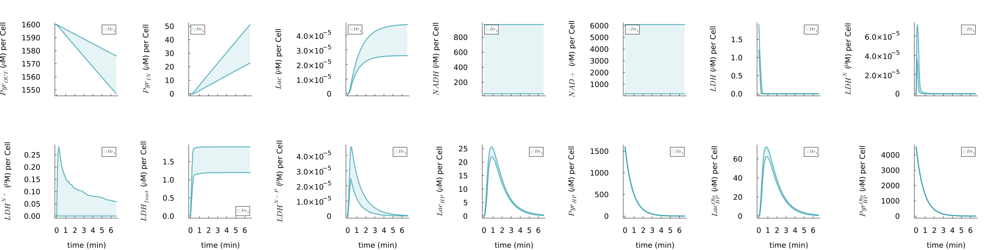

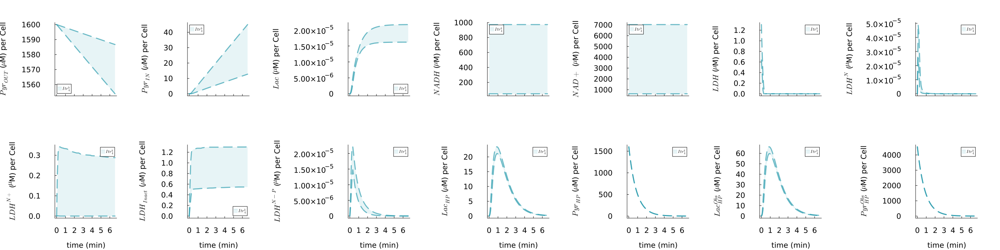

In [268]:
stss = [L"Pyr_{OUT}", L"Pyr_{IN}", L"Lac", L"NADH", L"NAD+", L"LDH", L"LDH^N", L"LDH^{N+}", L"LDH_{Inact}", L"LDH^{N-P}", L"Lac_{HP}", L"Pyr_{HP}", L"Lac_{HP}^{Obs}", L"Pyr_{HP}^{Obs}" ]
i=4 # Experiment
j=3 # Model Iteration

s=3 # Model State

ndd = 80

allXps = Array{Any}(undef, 14)

for j in 1:5

    for s in 1:14

        allXps[s] = plot()



            tmp1 = PriorQuant[1,j,s];
            tmp2 = PriorQuant[2,j,s];

            if j < 5
                if s > 7
                    plot!(collect(0:5:395)[1:ndd]./60, tmp1[1:ndd], label = "", color = ccpal[j],
                        linewidth=3, alpha = 0.6, xlabel = "time (min)", ylabel = stss[s]*" ("*L"\mu"*"M) per Cell", grid = false)
                    plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], label = "", color = ccpal[j], linewidth=3, alpha = 0.6)
                    plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], fillrange=convert.(Float64, tmp1), color=ccpal[j], fillalpha=0.1, linewidth = 0, label = nmsit[j])

                else
                    plot!(collect(0:5:395)[1:ndd]./60, tmp1[1:ndd], label = "", color = ccpal[j],
                        linewidth=3, alpha = 0.6, xlabel = "", ylabel = stss[s]*" ("*L"\mu"*"M) per Cell", grid = false, xformatter = :none)
                    plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], label = "", color = ccpal[j], linewidth=3, alpha = 0.6)
                    plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], fillrange=convert.(Float64, tmp1), color=ccpal[j], fillalpha=0.1, linewidth = 0, label = nmsit[j])

                end

            else

                if s > 7
                    plot!(collect(0:5:395)[1:ndd]./60, tmp1[1:ndd], label = "", color = ccpal[j],
                        linewidth=3, alpha = 0.6, xlabel = "time (min)", ylabel = stss[s]*" ("*L"\mu"*"M) per Cell", grid = false, linestyle=:dash)
                    plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], label = "", color = ccpal[j], linewidth=3, alpha = 0.6, linestyle=:dash)
                    plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], fillrange=convert.(Float64, tmp1), color=ccpal[j], fillalpha=0.1, linewidth = 0, label = nmsit[j], linestyle=:dash)

                else
                    plot!(collect(0:5:395)[1:ndd]./60, tmp1[1:ndd], label = "", color = ccpal[j],
                        linewidth=3, alpha = 0.6, xlabel = "", ylabel = stss[s]*" ("*L"\mu"*"M) per Cell", grid = false, xformatter = :none, linestyle=:dash)
                    plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], label = "", color = ccpal[j], linewidth=3, alpha = 0.6, linestyle=:dash)
                    plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], fillrange=convert.(Float64, tmp1), color=ccpal[j], fillalpha=0.1, linewidth = 0, label = nmsit[j], linestyle=:dash)

                end

            end

            

    end

    MMP = plot(allXps..., layout=(2,7), size = (2800,700), margin=14Plots.mm,xtickfont=font(14), 
        ytickfont=font(14), guidefont=font(14), titlefont=font(14))

        savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\SimsAllStats_Itr"*string(j)*".svg")

    display(MMP)
end



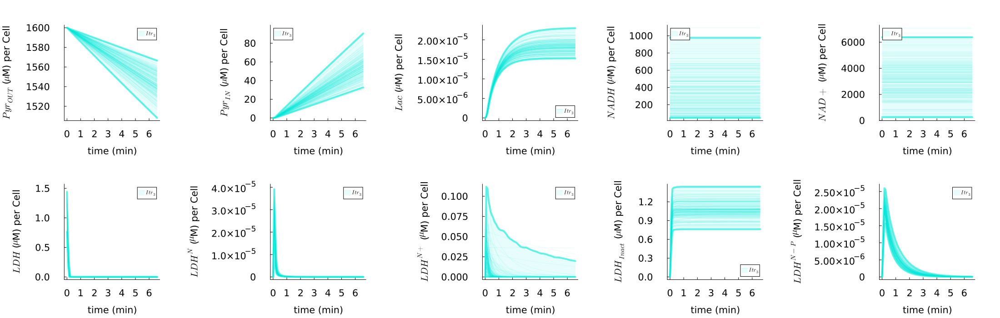

In [9]:
Random.seed!(234569)

ccpal = ["#ffaf4a", "#8edd4e", "#00ead7", "#118fa4", "#118fa4"];
nmsit = [L"Itr_1", L"Itr_2", L"Itr_3", L"Itr_4", L"Itr_4^b"];

stp = 3
ndd = 49
ndd2 = 46

stss = [L"Pyr_{OUT}", L"Pyr_{IN}", L"Lac", L"NADH", L"NAD+", L"LDH", L"LDH^N", L"LDH^{N+}", L"LDH_{Inact}", L"LDH^{N-P}", L"Lac_{HP}", L"Pyr_{HP}", L"Lac_{HP}^{Obs}", L"Pyr_{HP}^{Obs}" ]
i=4 # Experiment
j=3 # Model Iteration

s=3 # Model State

ndd = 80

allXps = Array{Any}(undef, 10)

for s in 1:10

    allXps[s] = plot()

    for j in 3


        tmp1 = PriorQuant[1,j,s];
        tmp2 = PriorQuant[2,j,s];

        plot!(collect(0:5:395)[1:ndd]./60, tmp1[1:ndd], label = "", color = ccpal[j],
            linewidth=4, alpha = 0.6, xlabel = "time (min)", ylabel = stss[s]*" ("*L"\mu"*"M) per Cell", grid = false)
        plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], label = "", color = ccpal[j], linewidth=4, alpha = 0.6)
        plot!(collect(0:5:395)[1:ndd]./60, tmp2[1:ndd], fillrange=convert.(Float64, tmp1), color=ccpal[j], fillalpha=0.1, linewidth = 0, label = nmsit[j])

        for samp in StatsBase.sample(1:4000, 200, replace = false)
            plot!(collect(0:5:395)[1:ndd]./60, SimsItr1All2[1,j,i-1][samp][:,s,1][1:ndd], label = "", color = ccpal[j], alpha=0.2,  linewidth=0.5)
        end

    end


end

PPA = plot(allXps..., layout=(2,5), size = (2200,700), margin=12Plots.mm,xtickfont=font(14), 
        ytickfont=font(14), guidefont=font(14), titlefont=font(14))

# savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\SimsStatesIter3Good.svg")

display(PPA)

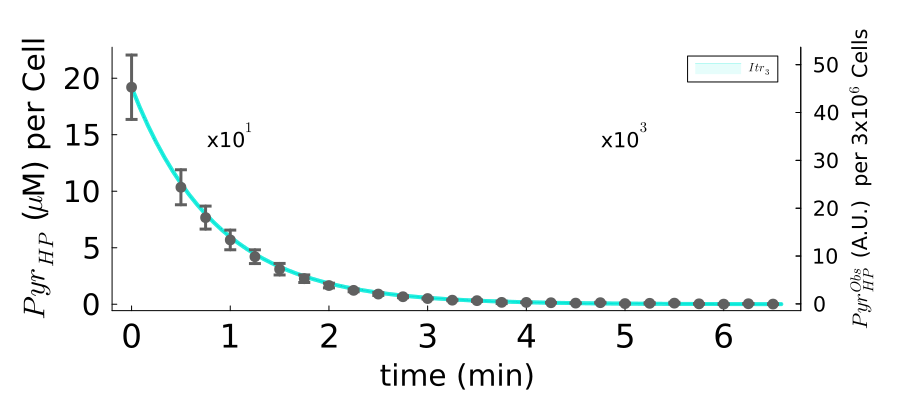

In [24]:
i=4 # Experiment
j=3 # Model Iteration



s=12

tmp1 = PriorQuant[1,j,s];
tmp2 = PriorQuant[2,j,s];

PyrP = plot(size = (900,400), width=3, 
        colour = "#b9b9b9ff", alpha = 1, xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=3)

plot!(collect(0:5:395)[1:ndd]./60, (tmp1[1:ndd]./10)*0.12, label = "", color = ccpal[j],
    linewidth=4, alpha = 0.6, xlabel = "time (min)", ylabel = stss[s]*" ("*L"\mu"*"M) per Cell", grid = false)
plot!(collect(0:5:395)[1:ndd]./60, (tmp2[1:ndd]./10)*0.12, label = "", color = ccpal[j], linewidth=4, alpha = 0.6)
plot!(collect(0:5:395)[1:ndd]./60, (tmp2[1:ndd]./10)*0.12, fillrange=convert.(Float64, (tmp1./10))*0.12, color=ccpal[j], fillalpha=0.1, linewidth = 0, label = nmsit[j],
ylims = (-0.5671368876531417, 19.775741851096694+(19.775741851096694*0.15)))

for samp in StatsBase.sample(1:4000, 200, replace = false)
    plot!(collect(0:5:395)[1:ndd]./60, (SimsItr1All2[1,j,i-1][samp][:,s,1][1:ndd]./10)*0.12, label = "", color = ccpal[j], alpha=0.2,  linewidth=0.5)
end

annotate!(1,15, "x10"*L"^1")


# Iam adding an extra zero to have the same shape and size than the Lactate one. In inkscape I will delete the extra zeros so it is ^3 as the annotation says
annotate!(5,15, "x10"*L"^3")

s=14
tmp1 = PriorQuant[1,j,s];
tmp2 = PriorQuant[2,j,s];

plot!(twinx(), collect(0:5:395)[1:ndd]./60, tmp1[1:ndd]./100, label = "", color = ccpal[j],
    linewidth=4, alpha = 0, xlabel = "", ylabel = stss[s]*" (A.U.)  per 3x10"*L"^6"*" Cells", grid = false,xtickfont=font(14), 
        ytickfont=font(14), guidefont=font(14), titlefont=font(14),
        ylim = (-141.3908181629704./100, 4664.964054706411./100+(4664.964054706411./100*0.15)))

scatter!(twinx(), allD[i][1:3:end,1]./60, allD[i][1:3:end,2]./100, yerror = allD[i][1:3:end,3]./100, label = "", yformatter = :none, colour="black", 
        ylim = (-141.3908181629704./100, 4664.964054706411./100+(4664.964054706411./100*0.15)),
        markersize=6, linewidth=3, color="#606060ff", markercolor="#606060ff", linecolor="#606060ff", markerstrokecolor="#606060ff")



savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\SimsStatesIter3Pyruvate.svg")

display(PyrP)

In [18]:
ylims(PyrP)

(-0.5671368876531417, 19.775741851096694)

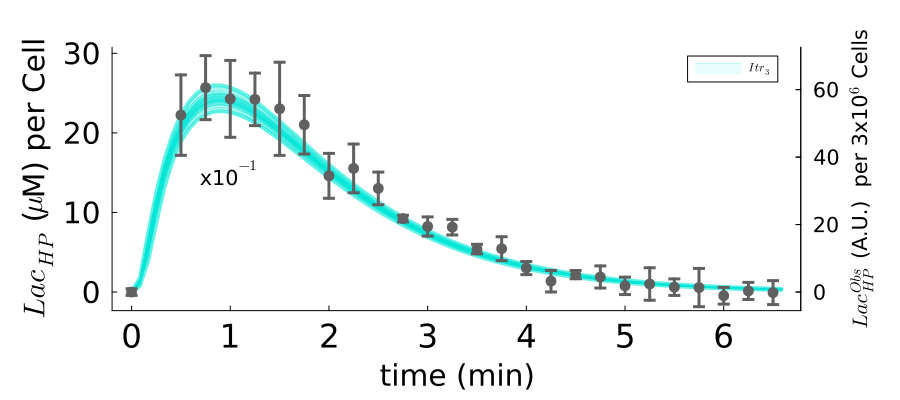

In [37]:
j=3 # Model Iteration

    # Dims = Up/Down, Observable, Experiment
PriorQuant = Array{Any}(undef,2,14,14);
for k in 1:5
    for m in 1:14
        lacPirorSims = zeros(size(SimsItr1All2[1,k,i-1][1])[1], 4000)
        [lacPirorSims[:,f] = SimsItr1All2[1,k,i-1][f][:,m,1] for f in 1:4000 ];

        PriorQuant[1,k,m] = [percentile(lacPirorSims[j,:], 99.5) for j in 1:size(lacPirorSims)[1]]; # Up
        PriorQuant[2,k,m] = [percentile(lacPirorSims[j,:], 0.5 ) for j in 1:size(lacPirorSims)[1]]; # Down
    end
end


s=11

tmp1 = PriorQuant[1,j,s];
tmp2 = PriorQuant[2,j,s];



PyrP = plot(size = (900,400), width=3, 
        colour = "#b9b9b9ff", alpha = 1, xtickfont=font(22), ytickfont=font(20), margins=10Plots.mm, guidefontsize = 20, markersize = 8, markerstrokewidth=3)

plot!(collect(0:5:395)[1:ndd]./60, (tmp1[1:ndd].*0.12).*10, label = "", color = ccpal[j],
    linewidth=4, alpha = 0.6, xlabel = "time (min)", ylabel = stss[s]*" ("*L"\mu"*"M) per Cell", grid = false)
plot!(collect(0:5:395)[1:ndd]./60, (tmp2[1:ndd].*0.12).*10, label = "", color = ccpal[j], linewidth=4, alpha = 0.6)
plot!(collect(0:5:395)[1:ndd]./60, (tmp2[1:ndd].*0.12).*10, fillrange=convert.(Float64, (tmp1.*0.12).*10), color=ccpal[j], fillalpha=0.1, linewidth = 0, label = nmsit[j],
    ylims=(-0.7791586465883693-(0.7791586465883693*2), 26.75111353286735+(26.75111353286735*0.15)))

for samp in StatsBase.sample(1:4000, 200, replace = false)
    plot!(collect(0:5:395)[1:ndd]./60, (SimsItr1All2[1,j,i-1][samp][:,s,1][1:ndd].*0.12).*10, label = "", color = ccpal[j], alpha=0.2,  linewidth=0.5)
end


annotate!(1,15, "x10"*L"^{-1}")


s=13
tmp1 = PriorQuant[1,j,s];
tmp2 = PriorQuant[2,j,s];

plot!(twinx(), collect(0:5:395)[1:ndd]./60, tmp1[1:ndd], label = "", color = ccpal[j],
    linewidth=4, alpha = 0, xlabel = "", ylabel = stss[s]*" (A.U.)  per 3x10"*L"^6"*" Cells", grid = false,xtickfont=font(14), 
        ytickfont=font(14), guidefont=font(14), titlefont=font(14),
        ylims=(-1.837895300349011-(1.837895300349011*2), 63.10107197864924+(63.10107197864924*0.15)))

scatter!(twinx(), allD[i][1:3:end,1]./60, allD[i][1:3:end,4], yerror = allD[i][1:3:end,5], label = "", yformatter = :none, colour="black",
        ylims=(-1.837895300349011-(1.837895300349011*2), 63.10107197864924+(63.10107197864924*0.15)),
        markersize=6, linewidth=3, color="#606060ff", markercolor="#606060ff", linecolor="#606060ff", markerstrokecolor="#606060ff")


savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\SimsStatesIter3Lactate.svg")

display(PyrP)

In [32]:
ylims(PyrP)

(-0.7791586465883693, 26.75111353286735)

# Pyruvate Concentrations

In [71]:
oedP = [0.6, 1.6, 12.8, 3.2, 40];

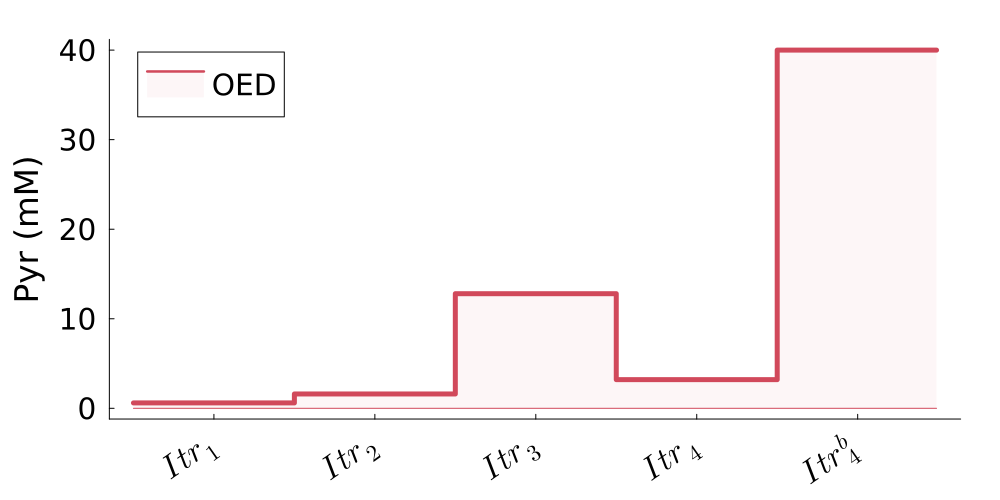

In [72]:
ppr = plot()

    # -----------------------------------------------------------------------------------------------------------------------------------

    plot!(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01), collect(3:0.01:4-0.01), collect(4:0.01:5-0.01)), 
        vcat(repeat([oedP[1]], 100), repeat([oedP[2]], 100), repeat([oedP[3]], 100), repeat([oedP[4]], 100), repeat([oedP[5]], 100)), linetype=:step, label = "",
        xticks = ([0.5,1.5,2.5,3.5,4.5], [L"Itr_1",L"Itr_2",L"Itr_3",L"Itr_4",L"Itr_4^b"]), grid = false, linewidth = 5, #yrange = (0,30),
        ylabel = "Pyr (mM)", margin=8Plots.mm,xtickfont=font(22), ytickfont=font(20), guidefont=font(22), titlefont=font(22),
        xrotation = 35, size = (1000,500), colour = "#d1495bff")
    
    plot!(vcat(collect(0:0.01:1-0.01), collect(1:0.01:2-0.01), collect(2:0.01:3-0.01), collect(3:0.01:4-0.01), collect(4:0.01:5-0.01)), zeros(500), fillrange = vcat(repeat([oedP[1]], 100), repeat([oedP[2]], 100), repeat([oedP[3]], 100), repeat([oedP[4]], 100), repeat([oedP[5]], 100)), 
            fillalpha=0.05, label = "OED", colour = "#d1495bff", legendfontsize=20,legend=:topleft)

savefig("C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\Paper\\Figures\\Figure6Stuff\\InputDesignProfiles.svg")

display(ppr)

# Tests...

In [73]:
function simAllCns(poster, nSamps = 10, res = 1, plott = false)
    tsC2 = vcat(collect(0:5:395));
    ts = 0:tsC2[end];
    samps = convert.(Int, tsC2);

    postDwn = poster[StatsBase.sample(1:size(poster)[1], nSamps, replace = false),:]

    scF = 1;

    PyrCons4 = collect(0:res:40);
    ObsPyrCons4 = PyrCons4.*(1000*0.12*scF);

    posterSimsO = Array{Any}(undef, length(PyrCons4))
    for i in 1:length(PyrCons4)
        tmp = zeros(length(samps),14,nSamps);
        for j in 1:nSamps
            ivss = [PyrCons4[i].*1000, 0, 0, postDwn[j,end-2], postDwn[j,end-1], postDwn[j,end], 0, 0, 0, 0, 0, PyrCons4[i].*1000, 0, PyrCons4[i].*(1000*0.12*scF)];
            SimOnTime1poster, SimOffTime1poster, SimAll1poster  = PyruvateHP_NMR_SolveAllCp_Scall(ts, vcat(postDwn[j,1:end-4], scF, zeros(1)), ivss, samps);
            tmp[:,:,j] = SimOnTime1poster[:,:,1]
        end
        posterSimsO[i] = tmp;
    end

    sumSimsO = zeros(nSamps, length(ObsPyrCons4));
    [sumSimsO[j,i] = trapz(samps, posterSimsO[i][:,13,j]) for i in 1:length(ObsPyrCons4) for j in 1:nSamps];

    lacSumQuantO = Array{Any}(undef,2,length(PyrCons4));
    for m in 1:length(PyrCons4)
        lacSumQuantO[1,m] = percentile(sumSimsO[:,m], 95); # Up
        lacSumQuantO[2,m] = percentile(sumSimsO[:,m], 5 ); # Down
    end

    if plott == true
        ppt = plot(PyrCons4, lacSumQuantO[1,:], label = "", color = "red3",
            xlabel = "Pyr (mM)", ylabel = "AUC Lac (A.U.)", grid = false)
        plot!(PyrCons4, lacSumQuantO[2,:], label = "", color = "red3", linewidth=0.6)
        plot!(PyrCons4, lacSumQuantO[2,:], fillrange=convert.(Float64, lacSumQuantO[1,:]), color="red3", fillalpha=0.2, linewidth = 0, label = "")

        display(ppt)
    end

    return(posterSimsO, sumSimsO, lacSumQuantO)
end

simAllCns (generic function with 4 methods)

In [74]:
ss(t,p) = p[1].*(p[2].*exp.(-t.*p[3]).+p[4].*exp.(-t.*p[5]))

pp = [7.928769645922547, 64.44544230996016, 0.04371746617991178, -66.48238441567781, 0.6994846456396232];

samps = 400#1000
disc1 = 0.2#0.2
mainP = "C:\\IBECPostDocDrive\\2024_01_16_NCvsKR\\DataProcessingInference\\ExperimentalBayesianOED_FINAL\\ResultsPostAnal\\"
PyrCons4 = collect(0:disc1:40);
ObsPyrCons4 = PyrCons4.*(1000*0.12*1);


rep = false

posterSimsRAll2, sumSimsRAll2, lacSumQuantRAll2 = Array{Any}(undef, length(pyrs)), Array{Any}(undef, length(pyrs)), Array{Any}(undef, length(pyrs))


for i in 1:length(pyrs)
    
    filch = "SimulationsPosteriorDiffPyrConcAll_Itr2_Itr"*string(pyrs[i])*".jld"

    if isfile(mainP*filch) && rep == false
        println(1)
        tt1 = JLD2.load(mainP*filch);
        posterSimsR, sumSimsR, lacSumQuantR = tt1["posterSimsR"], tt1["sumSimsR"], tt1["lacSumQuantR"];
        posterSimsRAll2[i], sumSimsRAll2[i], lacSumQuantRAll2[i] = posterSimsR, sumSimsR, lacSumQuantR

    elseif !isfile(mainP*filch) || rep == true
        println(2)
        Random.seed!(456561325)
        posterSimsR, sumSimsR, lacSumQuantR = simAllCns(postersItr2[i], samps, disc1, false);

        JLD2.save(mainP*filch, "posterSimsR", posterSimsR, "sumSimsR", sumSimsR, "lacSumQuantR", lacSumQuantR);

        posterSimsRAll2[i], sumSimsRAll2[i], lacSumQuantRAll2[i] = posterSimsR, sumSimsR, lacSumQuantR

    end
end

1
1
1
1
1
1
1
1
1
1
1
1
1


In [75]:
datt = ss(0:disc1:40, pp)[2:end]

pyrlacsims = Array{Any}(undef, length(postersItr2), length(datt), samps)
diffspred = Array{Any}(undef, length(postersItr2), length(datt), samps)

diffsAll = zeros(length(postersItr2))

i= 3 # posterior
j = 1 # conce
m = 1 # sample

for i in 1:length(postersItr2)
    tmp1 = zeros(length(postersItr2), samps)
    for m in 1:samps
        for j in 1:length(datt)
            pyrlacsims[i,j,m] = trapz(collect(0:5:395), posterSimsRAll2[i][2:end][j][:,13,m])
        end
        diffspred[i,:,m] = sqrt.((pyrlacsims[i,:,m] - datt) .^ 2)
        tmp1[i,m] = sum(diffspred[i,:,m])
    end
    diffsAll[i] = mean(tmp1[i,:])
end

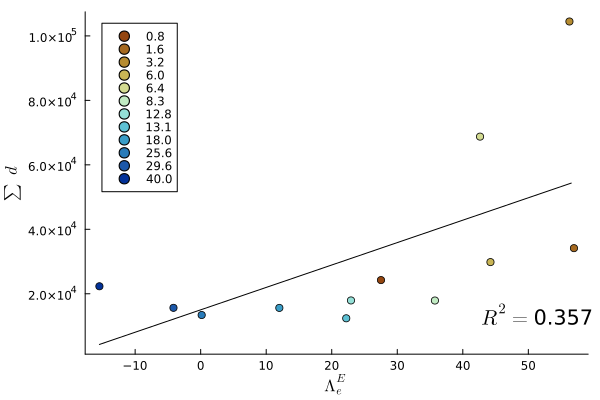

In [76]:
data = DataFrame(X=objs2[1:end], Y=diffsAll[1:end])
ols = GLM.lm(@formula(Y ~ X), data)


clss = cgrad(:roma, 13, categorical = true)


PPCvsU = plot(minimum(objs2[1:end]):maximum(objs2[1:end]), predict(ols, DataFrame(X = minimum(objs2[1:end]):maximum(objs2[1:end]))), 
        label = "", grid = false, colour = "black", 
        ylabel = L"\sum d", xlabel = L"\Lambda^E_e")
for i in 2:length(diffsAll)
    scatter!([objs2[i]], [diffsAll[i]], label = cns2[i], grid = false, colour = clss[i])
end

annotate!(maximum(objs2[1:end])*0.9, minimum(diffsAll[1:end])*1.1, L"R^2 = "*string(round(r2(ols), digits=3)), 14)

display(PPCvsU)

In [77]:
i= 3 # posterior
j = 1 # conce
m = 1 # sample

# tmp1 = zeros(length(postersItr2), samps)
# pyrlacsims[i,j,m] = trapz(collect(0:5:395), posterSimsRAll2[i][2:end][j][:,13,m])
# diffspred[i,:,m] = sqrt.((pyrlacsims[i,:,m] - datt) .^ 2)

# tmp1[i,m] = sum(diffspred[i,:,m])

diffsAll

13-element Vector{Float64}:
  36374.73753061625
  24235.06850925505
  34144.719048977204
 104476.86410525412
  29817.16633341031
  68754.29074313017
  17895.999855096772
  17917.67659354552
  12379.83434669618
  15604.0307390862
  13396.181581994251
  15628.287894317991
  22316.223369459658

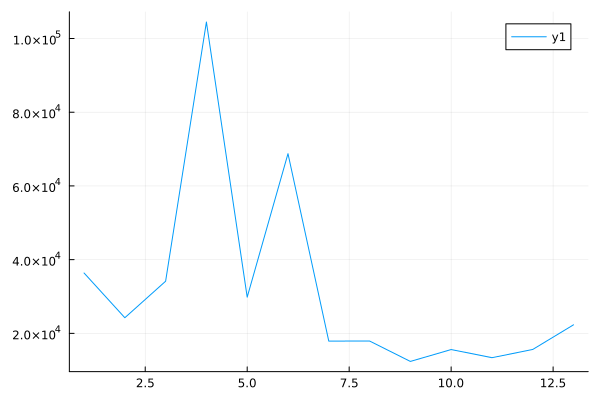

In [78]:
plot(diffsAll)

In [79]:
size(diffspred)

(13, 200, 400)

In [80]:
i= 3 # posterior
j = 1 # conce - sum
m = 1 # sample - mean

[sum(diffspred[i,:,m]) for i in 1:length(postersItr2) for m in 1:samps]

5200-element Vector{Float64}:
 35588.391640740534
 36820.73447970339
 38189.115187109586
 36324.62942620981
 36663.31331212691
 37422.77388479562
 38423.152660535896
 38143.89244475862
 37139.270413484366
 37092.42629091157
 36506.64561694287
 37433.59401608418
 38650.0105951792
     ⋮
 21506.799964531154
 22167.171340148423
 22114.915686429926
 21701.141856342336
 22113.18514052089
 21975.84734408304
 22766.076036336435
 23068.365161533446
 22422.798197404132
 23035.248515607957
 22867.565834990473
 21609.571959300727

In [ ]:
objs2

13-element Vector{Float64}:
  12.176337243715722
  27.515237283646286
  56.96160454044898
  56.27234412056447
  44.22135270449853
  42.63111506259747
  35.744180395266866
  22.936525538064778
  22.21440279452589
  12.004692376667908
   0.15252413323476555
  -4.150513389219121
 -15.452191786962509

200-element Vector{Float64}:
  48.21845061909468
 103.6418473877855
 151.2923180027178
 192.18931196641364
 227.21914673525626
 257.1523887494018
 282.6589653287029
 304.3213036750028
 322.64575454634036
 338.0725245428686
   ⋮
  95.35112977152768
  94.5210619477929
  93.69822017992173
  92.88254156235391
  92.07396373714565
  91.27242488920251
  90.47786374155376
  89.6902195506677
  88.90943210180806

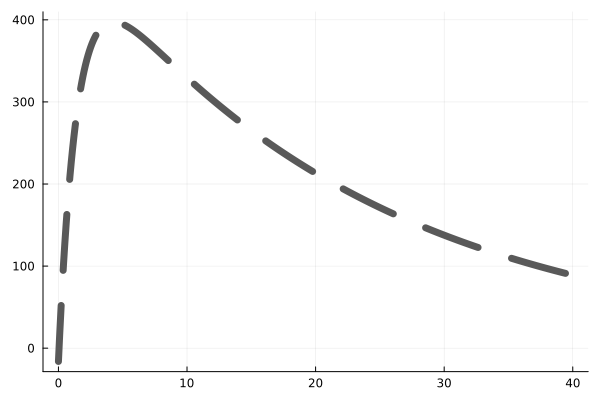

In [ ]:
pp1 = plot(0:0.1:40, ss(0:0.1:40, pp), label="", colour="#595959ff", linewidth = 7,  linestyle = :dash)